# CropAugment AI: Crop Disease Image Augmenter
**Course:** Generative AI Project  |  **Technique Category:** Data Augmentation (domain-aware transforms + Img2Img diffusion)  |  **Domain:** Agriculture  |  **Team 2**

---
## 1. Problem Statement
Crop-disease classifiers trained on limited field photos struggle to generalize across **lighting**, **growth stage**, and **camera angle** variation. Collecting and annotating more real-world field images across seasons and conditions is costly.

**Use case:** a crop-disease image augmentation pipeline that improves classifier robustness *without* additional field data collection.

**Our solution (`CropAugment AI`):** a hybrid **domain-aware + generative augmentation pipeline** that expands a deliberately small training set (10 % regime) and is evaluated against (i) a no-augmentation baseline, (ii) a *standard* torchvision-augmentation baseline, (iii) in-family and **never-seen-in-training** stress tests, and (iv) real outdoor field photos (**PlantDoc**).

## 2. How this notebook maps to the project brief
| Brief requirement | Where it is addressed |
| :--- | :--- |
| Robustness to **lighting** variation | `change_lighting` (brightness / contrast / cast shadows / glare) → Sections 7, 9-10 |
| Robustness to **camera-angle** variation | `change_angle` (rotation ±40°, mirror, shear) → Sections 7, 9-10 |
| Robustness to **growth-stage** variation | `change_growth_stage` (scale + chlorophyll tint; *a proxy*, see Limitations) → Sections 7, 9-10 |
| Lab → **field** gap (the real problem) | `composite_background` (leaf segmentation + procedural soil/foliage backgrounds, Model B2) and PlantDoc evaluation → Sections 7, 10, 14, 17 |
| **Generative AI** component | Stable Diffusion v1.4 Img2Img + semantic-consistency gate (Model C) → Sections 15-16 |
| Classifier-robustness **evidence** | 8 stress tests (4 in-family + 4 out-of-distribution), 3 seeds with *different* data subsets, paired bootstrap CIs → Sections 11-19 |
| Reusable **pipeline** | `cropaugment.py` (augmentation + ResNet-18 loader/predictor), Gradio demo with live classification → Sections 7, 21-22 |

## 3. Experimental design (controlled 10 % low-data regime)
All models share an identical compute budget (`SAMPLES_PER_EPOCH × EPOCHS` image updates), the same ImageNet-pretrained ResNet-18, and **3 seeds. Each seed draws its own 10 % subset, its own augmented copies and its own diffusion samples**, so the reported ± reflects data-sampling variance as well as initialisation variance.

| Model | Training data |
| :--- | :--- |
| **A** | original 10 % photos only |
| **A+** | original 10 % + *standard* torchvision augmentation on the fly (control) |
| **B** | original 10 % + 4× domain-pipeline copies (lighting / angle / growth stage) |
| **B2** | B + 2× background-composited copies per photo (lab → field-like clutter) |
| **C** | B + confidence-filtered Stable Diffusion images (up-weighted to a fixed share of draws) |

## 4. Research questions
* **Q1:** Does the domain pipeline (B) improve robustness over no augmentation (A) *and* over standard augmentation (A+)?
* **Q2:** Do confidence-filtered Stable Diffusion images (C) add gains over B?
* **Q3:** Does augmentation improve recall on **minority (rare) disease classes**?
* **Q4:** Do the gains transfer to **unseen real outdoor field photos** (PlantDoc)?
* **Q5:** Does background compositing (B2) narrow the lab → field gap better than B?

### Stress-test taxonomy (important for interpreting results)
* **In-family** (`lighting`, `angle`, `growth`, `field mix`): same *kinds* of transforms the pipeline trains on, but with different, stronger parameters and different implementations. Gains here are expected and show interpolation robustness only.
* **Out-of-distribution** (`quality`, `color+noise`, `occlusion`, `clutter`): corruption types **none of the models were trained on**. `clutter` uses the same leaf-segmentation helper as B2 but pastes onto mosaics of real leaf photos instead of procedural soil, so it is only partly related to B2.
* **Real field** (PlantDoc): independent real-world photos, the most credible test.

> **Execution (Google Colab):** `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`. Upload your dataset ZIP (one folder per class) when prompted (or press **Cancel** for a tiny synthetic demo dataset). PlantDoc (~2 GB) is cloned from GitHub, so the internet must be on. A full run (3 seeds, 5 models, 3×diffusion sets) takes roughly 1.5-2.5 h on a T4. Set `QUICK_MODE = True` in Section 6 for a ~15-minute smoke test (1 seed, shorter training; **not** for reporting). After the run, use `File > Download > Download .ipynb` so the outputs are saved with the notebook.

## 5. Install and Import Libraries

In [1]:
!pip -q install diffusers transformers accelerate safetensors gradio

import os, io, re, gc, sys, json, math, random, hashlib, zipfile, subprocess, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance, ImageFilter, ImageDraw
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, RandomSampler, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import f1_score, recall_score, confusion_matrix
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on device: {device.upper()}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: no GPU detected. Enable a T4 GPU (Runtime > Change runtime type); training and diffusion will be extremely slow on CPU.")

Running on device: CUDA
GPU: Tesla T4


## 6. Experiment Configuration & Hyperparameters
All tunable parameters are centralised here for reproducibility. **Leave `QUICK_MODE = False` for the final reported run.**

In [2]:
QUICK_MODE = False          # True = fast smoke test only (1 seed, short training). Never report QUICK_MODE numbers.

SEED = 42                   # data split / stress-test subset seed
SEEDS = [0, 1, 2]           # independent runs: each seed has its own 10% subset, augmented copies, diffusion samples
LOW_FRAC = 0.10             # data-scarcity regime: use only 10% of the training split
COPIES = 4                  # domain-pipeline copies per original photo (Model B)
BG_COPIES = 2               # extra background-composited copies per original photo (Model B2)
EPOCHS = 8
SAMPLES_PER_EPOCH = 2400    # fixed gradient-update budget for ALL models
BATCH = 32
LR = 3e-4
TEST_N = 1000               # validation images per stress-test condition

# Near-duplicate grouping (leakage control): 16x16 dHash = 256 bits; images within NEAR_DUP_T bits
# (under any of the 8 rotations/flips) are forced into the same split.
NEAR_DUP_T = 6

# Generative AI (Stable Diffusion Img2Img)
DIFF_PER_CLASS = 15         # candidate AI images per class PER SEED
DIFF_STRENGTH = 0.35        # low denoising strength preserves lesions
DIFF_STEPS = 25
FILTER_CONF = 0.80          # semantic-consistency threshold (falls back to 0.65 only if too few pass)
MIN_ACCEPTED_TOTAL = 10
DIFF_SHARE = 0.10           # accepted diffusion images make up this share of Model C's training draws

FIELD_MAX_PER_CLASS = 60    # PlantDoc photos per matched class

if QUICK_MODE:
    SEEDS = [0]; EPOCHS = 3; TEST_N = 300; DIFF_PER_CLASS = 4; FIELD_MAX_PER_CLASS = 20
    print("*** QUICK_MODE ON: results are a smoke test only ***")

BASE = Path("/content/CropAugmentAI")
RAW = BASE / "raw"
PIPE_DIR = BASE / "pipeline_images"
BG_DIR = BASE / "background_images"
DIFF_DIR = BASE / "diffusion_images"
RESULTS = BASE / "results"
for folder in [RAW, PIPE_DIR, BG_DIR, DIFF_DIR, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(SEED)

## 7. Augmentation Module (`cropaugment.py`)
The augmentation library is written to disk **first** and then imported, so the exact file that is exported with the submission is the code used in every experiment. It contains the three domain transforms (lighting, camera angle, growth stage), the **background-compositing** transform (leaf segmentation + procedural field backgrounds), and ResNet-18 loader / predictor helpers.

In [3]:
%%writefile cropaugment.py
"""CropAugment AI - domain-aware crop-disease image augmentation (+ optional ResNet-18 inference helpers).

Augmentation part needs only: numpy, Pillow, scipy.   Classifier helpers additionally need: torch, torchvision.
"""
import json, random, os
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps, ImageEnhance, ImageFilter, ImageDraw


def avg_color(img):
    return img.resize((1, 1), Image.BOX).getpixel((0, 0))


# ---------- 1. LIGHTING ----------
def change_lighting(img, rng):
    img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.5, 1.5))
    img = ImageEnhance.Contrast(img).enhance(rng.uniform(0.7, 1.3))
    if rng.random() < 0.5:                       # cast shadow patch
        w, h = img.size
        mask = Image.new("L", (w, h), 0)
        points = [(rng.randint(0, w), rng.randint(0, h)) for _ in range(4)]
        ImageDraw.Draw(mask).polygon(points, fill=int(255 * rng.uniform(0.3, 0.6)))
        mask = mask.filter(ImageFilter.GaussianBlur(w * 0.04))
        dark = ImageEnhance.Brightness(img).enhance(0.3)
        img = Image.composite(dark, img, mask)
    if rng.random() < 0.3:                       # specular sun glare
        w, h = img.size
        mask = Image.new("L", (w, h), 0)
        cx, cy, r = rng.randint(0, w), rng.randint(0, h), int(w * 0.2)
        ImageDraw.Draw(mask).ellipse((cx - r, cy - r, cx + r, cy + r), fill=150)
        mask = mask.filter(ImageFilter.GaussianBlur(w * 0.08))
        bright = ImageEnhance.Brightness(img).enhance(1.8)
        img = Image.composite(bright, img, mask)
    return img


# ---------- 2. CAMERA ANGLE ----------
def change_angle(img, rng):
    img = img.rotate(rng.uniform(-40, 40), resample=Image.BILINEAR, fillcolor=avg_color(img))
    if rng.random() < 0.5:
        img = ImageOps.mirror(img)
    shear_x = rng.uniform(-0.2, 0.2)
    shear_y = rng.uniform(-0.2, 0.2)
    img = img.transform(img.size, Image.AFFINE, (1, shear_x, 0, shear_y, 1, 0), Image.BILINEAR,
                        fillcolor=avg_color(img))
    return img


# ---------- 3. GROWTH STAGE (proxy: scale + chlorophyll tint) ----------
def change_growth_stage(img, rng, strength=None):
    w, h = img.size
    if strength is None:
        strength = rng.uniform(0.2, 0.6)
    if rng.random() < 0.5:   # YOUNG leaf: smaller, lighter yellow-green
        s = 1 - strength * 0.7
        small = img.resize((int(w * s), int(h * s)))
        border_colour = tuple(int(c) for c in np.asarray(img.resize((1, 1))).reshape(3))
        canvas = Image.new("RGB", (w, h), border_colour)
        canvas.paste(small, ((w - small.size[0]) // 2, (h - small.size[1]) // 2))
        img = ImageEnhance.Brightness(canvas).enhance(1 + 0.3 * strength)
        arr = np.asarray(img).astype(np.float32) * np.array([1 + 0.2 * strength, 1 + 0.05 * strength, 1 - 0.2 * strength])
    else:                    # MATURE leaf: larger, darker green
        s = 1 - strength * 0.4
        cw, ch = int(w * s), int(h * s)
        left, top = (w - cw) // 2, (h - ch) // 2
        img = img.crop((left, top, left + cw, top + ch)).resize((w, h))
        img = ImageEnhance.Brightness(img).enhance(1 - 0.3 * strength)
        arr = np.asarray(img).astype(np.float32) * np.array([1 - 0.15 * strength, 1 + 0.02 * strength, 1 - 0.15 * strength])
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))


# ---------- 4. BACKGROUND COMPOSITING (lab -> field-like clutter) ----------
_PALETTES = [((110, 80, 55), (70, 50, 35)),    # soil
             ((70, 110, 50), (40, 75, 35)),    # grass / canopy
             ((95, 95, 60), (60, 60, 40)),     # dry vegetation
             ((130, 110, 85), (90, 75, 60))]   # sandy soil / mulch


def _smooth_noise(size, nrng, cells):
    n = nrng.random((cells, cells)).astype(np.float32)
    im = Image.fromarray((n * 255).astype(np.uint8)).resize((size, size), Image.BICUBIC)
    return np.asarray(im, dtype=np.float32) / 255.0


def make_field_background(size, rng):
    """Procedural soil / grass / foliage background (multi-scale noise + green blobs + grain)."""
    nrng = np.random.default_rng(rng.randint(0, 2 ** 31 - 1))
    c1, c2 = (np.array(c, dtype=np.float32) for c in rng.choice(_PALETTES))
    t = 0.5 * _smooth_noise(size, nrng, 6) + 0.3 * _smooth_noise(size, nrng, 20) + 0.2 * _smooth_noise(size, nrng, 56)
    arr = c2 + (c1 - c2) * t[..., None] + nrng.normal(0, 6, (size, size, 3))
    bg = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    d = ImageDraw.Draw(bg)
    for _ in range(rng.randint(3, 9)):           # background foliage blobs
        cx, cy = rng.randint(0, size), rng.randint(0, size)
        rx, ry = rng.randint(size // 12, size // 4), rng.randint(size // 16, size // 6)
        g = rng.randint(70, 140)
        d.ellipse((cx - rx, cy - ry, cx + rx, cy + ry), fill=(int(g * 0.55), g, int(g * 0.4)))
    bg = bg.filter(ImageFilter.GaussianBlur(size * 0.006))
    return ImageEnhance.Brightness(bg).enhance(rng.uniform(0.7, 1.2))


def leaf_mask(img, min_frac=0.08, max_frac=0.97):
    """Rough foreground mask for studio-background leaf photos (colour distance from the border colour).
    Returns an 'L' PIL mask (feathered) or None if the segmentation looks unreliable."""
    from scipy import ndimage as ndi
    a = np.asarray(img.convert("RGB")).astype(np.float32)
    border = np.concatenate([a[:3].reshape(-1, 3), a[-3:].reshape(-1, 3),
                             a[:, :3].reshape(-1, 3), a[:, -3:].reshape(-1, 3)])
    bg = np.median(border, axis=0)
    m = np.abs(a - bg).max(axis=2) > 28
    m = ndi.binary_opening(m, iterations=1)
    m = ndi.binary_closing(m, iterations=3)
    m = ndi.binary_fill_holes(m)
    lab, n = ndi.label(m)
    if n == 0:
        return None
    sizes = ndi.sum(m, lab, index=np.arange(1, n + 1))
    m = lab == (1 + int(np.argmax(sizes)))
    frac = float(m.mean())
    if frac < min_frac or frac > max_frac:
        return None
    return Image.fromarray((m * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(1.5))


def composite_background(img, rng):
    """Paste the segmented leaf (random scale/position) on a procedural field background. None if mask fails."""
    img = img.convert("RGB").resize((224, 224))
    mask = leaf_mask(img)
    if mask is None:
        return None
    s = rng.uniform(0.6, 1.0)
    sw = int(224 * s)
    fg, mk = img.resize((sw, sw)), mask.resize((sw, sw))
    bg = make_field_background(224, rng)
    bg.paste(fg, (rng.randint(0, 224 - sw), rng.randint(0, 224 - sw)), mk)
    return bg


def augment_background(img, rng):
    """Background composite followed by optional lighting / angle shifts. Returns (image, tag) or (None, None)."""
    out = composite_background(img, rng)
    if out is None:
        return None, None
    tag = "background"
    if rng.random() < 0.5:
        out = change_lighting(out, rng); tag += "+lighting"
    if rng.random() < 0.5:
        out = change_angle(out, rng); tag += "+angle"
    return out, tag


# ---------- COMPOSITE PIPELINE ----------
def augment_one(img, rng):
    img = img.resize((224, 224))
    choice = rng.choice(["lighting", "angle", "growth", "lighting+angle", "growth+lighting", "all"])
    if "lighting" in choice or choice == "all":
        img = change_lighting(img, rng)
    if "angle" in choice or choice == "all":
        img = change_angle(img, rng)
    if "growth" in choice or choice == "all":
        img = change_growth_stage(img, rng)
    return img, choice


def augment_folder(in_dir, out_dir, copies=4, seed=0, with_background=False):
    """Augment every image in in_dir (one sub-folder per class) and save to out_dir. Returns #images written."""
    rng = random.Random(seed)
    n = 0
    for f in sorted(Path(in_dir).rglob("*")):
        if f.suffix.lower() in (".jpg", ".jpeg", ".png"):
            img = Image.open(f).convert("RGB")
            dest = Path(out_dir) / f.parent.name
            dest.mkdir(parents=True, exist_ok=True)
            for k in range(copies):
                aug = None
                if with_background and k % 2 == 1:
                    aug, _ = augment_background(img, rng)
                if aug is None:
                    aug, _ = augment_one(img, rng)
                aug.save(dest / f"{f.stem}_aug{k}.jpg", quality=95)
                n += 1
    return n


# ---------- CLASSIFIER HELPERS (torch imported lazily) ----------
def build_resnet18(num_classes, pretrained=False):
    import torch.nn as nn
    from torchvision import models
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m


def eval_transform():
    from torchvision import transforms
    return transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                               transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


def load_classifier(weights_path="cropaugment_resnet18.pt", classes_path="classes.json", device=None):
    import torch
    classes = json.load(open(classes_path))
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = build_resnet18(len(classes))
    model.load_state_dict(torch.load(weights_path, map_location=device))
    return model.to(device).eval(), classes


def predict(model, classes, img, topk=3):
    """Return [(class_name, probability), ...] for one PIL image."""
    import torch
    device = next(model.parameters()).device
    x = eval_transform()(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0].cpu().numpy()
    idx = np.argsort(-p)[:topk]
    return [(classes[i], float(p[i])) for i in idx]

Writing cropaugment.py


In [4]:
sys.path.insert(0, os.getcwd())
importlib.invalidate_caches()
import cropaugment
importlib.reload(cropaugment)
from cropaugment import (avg_color, change_lighting, change_angle, change_growth_stage,
                         augment_one, augment_background, composite_background, leaf_mask)
print("cropaugment module loaded from:", cropaugment.__file__)

cropaugment module loaded from: /content/cropaugment.py


## 8. Load Dataset & Leakage-Safe Splitting
We load the crop-disease dataset (one folder per class). Leakage is controlled in **two** layers:
1. **Exact duplicates** (MD5) are removed within each class.
2. **Near-duplicates** (re-saved, rescaled, rotated or mirrored copies of the same photo) are detected with a perceptual difference-hash compared under all 8 rotations/flips. Near-duplicate images are placed in the same *group* and the train/validation split is **group-aware** (`StratifiedGroupKFold`), so a photo and its near-copies can never straddle the split. We then *verify* the result with a direct cross-split distance check.

Limitation: perceptual hashing catches copies of the same photo, not different photographs of the same physical leaf (that needs capture metadata, which this dataset lacks).

In [6]:
EXTS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]


def make_demo_dataset(root):
    # Synthetic leaf dataset so the pipeline stays runnable without an upload (smoke test only)
    classes = [
        "Tomato_Early_blight",
        "Tomato_healthy",
        "Potato_Late_blight",
        "Corn_Common_rust",
    ]
    rng = np.random.default_rng(0)
    for ci, name in enumerate(classes):
        (root / name).mkdir(parents=True, exist_ok=True)
        n_imgs = 45 if ci < 2 else 24
        for i in range(n_imgs):
            arr = np.full((128, 128, 3), 185.0) + rng.normal(
                0, 6, (128, 128, 3)
            )
            img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
            draw = ImageDraw.Draw(img)
            draw.ellipse(
                (20, 10, 108, 118),
                fill=(int(70 + 15 * ci), int(140 - 12 * ci), 55),
            )
            for _ in range(2 + 2 * ci):
                x = int(rng.integers(35, 95))
                y = int(rng.integers(25, 100))
                r = int(rng.integers(3, 8))
                draw.ellipse((x - r, y - r, x + r, y + r), fill=(115, 65, 35))
            img.save(root / name / f"demo_{i:03d}.jpg")


def get_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        h.update(f.read())
    return h.hexdigest()


if (
    not any(RAW.rglob("*.jpg"))
    and not any(RAW.rglob("*.png"))
    and not any(RAW.rglob("*.jpeg"))
):
    from google.colab import drive

    drive.mount("/content/drive")
    MYDRIVE = Path("/content/drive/MyDrive")

    matches = [p for p in MYDRIVE.rglob("*.zip") if "crop" in p.name.lower()]
    if not matches:
        all_zips = list(MYDRIVE.rglob("*.zip"))
        print("ZIP files found in MyDrive:", [str(p) for p in all_zips])
        print(
            "Top-level items in MyDrive:", [p.name for p in MYDRIVE.iterdir()]
        )
        raise FileNotFoundError(
            "No zip with 'crop' in its name found. Check the printed list"
            " above."
        )

    DRIVE_ZIP = matches[0]
    print(f"Found ZIP: {DRIVE_ZIP}")
    with zipfile.ZipFile(DRIVE_ZIP, "r") as z:
        z.extractall(RAW)
    print(f"Extracted {DRIVE_ZIP} into {RAW}")

class_folders = []
for d in sorted(RAW.rglob("*")):
    if d.is_dir() and any(f.suffix.lower() in EXTS for f in d.iterdir()):
        class_folders.append(d)

CLASSES = sorted(set(d.name for d in class_folders))
class_to_idx = {name: i for i, name in enumerate(CLASSES)}
NC = len(CLASSES)

ALL_ITEMS, HASH = [], {}
seen = set()
n_files = n_dup = 0
for d in class_folders:
    for f in sorted(d.iterdir()):
        if f.suffix.lower() not in EXTS:
            continue
        n_files += 1
        h = get_md5(f)
        if (d.name, h) in seen:
            n_dup += 1
            continue
        seen.add((d.name, h))
        ALL_ITEMS.append((str(f), class_to_idx[d.name]))
        HASH[str(f)] = h

print(
    f"Files scanned: {n_files} | Exact duplicates removed: {n_dup} | Unique"
    f" images: {len(ALL_ITEMS)} | Classes: {NC}"
)
assert (
    len(ALL_ITEMS) > 0 and NC >= 2
), "Dataset not loaded correctly."

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found ZIP: /content/drive/MyDrive/crop_dataset.zip
Extracted /content/drive/MyDrive/crop_dataset.zip into /content/CropAugmentAI/raw
Files scanned: 41276 | Exact duplicates removed: 20652 | Unique images: 20624 | Classes: 15


In [7]:
# ---- Near-duplicate detection: 16x16 dHash under all 8 dihedral variants, grouped per class ----
def dihedral_hashes(path, size=16):
    im = Image.open(path)
    try:
        im.draft("L", (160, 160))
    except Exception:
        pass
    g = im.convert("L").resize((64, 64), Image.BILINEAR)
    out = []
    for flip in (False, True):
        base = ImageOps.mirror(g) if flip else g
        for k in range(4):
            v = base.rotate(90 * k).resize((size + 1, size), Image.BILINEAR)
            a = np.asarray(v, dtype=np.int16)
            out.append((a[:, 1:] > a[:, :-1]).astype(np.uint8).ravel())
    return np.stack(out)                      # (8, size*size)

def hamming_min_over_variants(Ha, Hb):
    """Ha: (n,B) uint8 hashes (identity variant); Hb: (m,8,B). Returns (n,m) min Hamming distance over the 8 variants."""
    A = Ha.astype(np.float32); B = A.shape[1]
    best = np.full((A.shape[0], Hb.shape[0]), B, dtype=np.float32)
    for v in range(8):
        Bv = Hb[:, v, :].astype(np.float32)
        best = np.minimum(best, B - (A @ Bv.T + (1 - A) @ (1 - Bv).T))
    return best

by_class = {}
for i, (p, y) in enumerate(ALL_ITEMS):
    by_class.setdefault(y, []).append(i)

GROUPS = np.zeros(len(ALL_ITEMS), dtype=int)
HSTORE = {}
next_gid = 0
for y, idxs in sorted(by_class.items()):
    H = np.stack([dihedral_hashes(ALL_ITEMS[i][0]) for i in idxs])        # (n, 8, B) uint8
    HSTORE[y] = (np.array(idxs), H)
    adj = hamming_min_over_variants(H[:, 0, :], H) <= NEAR_DUP_T
    ncomp, lab = connected_components(csr_matrix(adj), directed=False)
    GROUPS[idxs] = lab + next_gid
    next_gid += ncomp
    print(f"  [{y+1}/{NC}] {CLASSES[y]}: {len(idxs)} images -> {ncomp} groups")

sizes = np.bincount(GROUPS)
multi = sizes[sizes > 1]
print(f"\nNear-duplicate groups with >1 image: {len(multi)} | images inside them: {int(multi.sum())} "
      f"({100*multi.sum()/len(ALL_ITEMS):.2f}% of the dataset) | largest group: {int(sizes.max())}")
if sizes.max() > 0.02 * len(ALL_ITEMS):
    print("WARNING: one group is unusually large (hash collisions on near-identical backgrounds?); lower NEAR_DUP_T.")

# Show a few detected near-duplicate groups as evidence
ex_groups = [g for g in np.argsort(-sizes)[:4] if sizes[g] > 1]
if ex_groups:
    fig, axes = plt.subplots(len(ex_groups), 3, figsize=(7.5, 2.5 * len(ex_groups)), squeeze=False)
    for r, g in enumerate(ex_groups):
        members = np.where(GROUPS == g)[0][:3]
        for c in range(3):
            axes[r, c].axis("off")
            if c < len(members):
                axes[r, c].imshow(Image.open(ALL_ITEMS[members[c]][0]).convert("RGB"))
                axes[r, c].set_title(f"group {g} (size {sizes[g]})", fontsize=8)
    plt.suptitle("Examples of detected near-duplicate groups", fontweight="bold")
    plt.tight_layout(); plt.savefig(RESULTS / "near_duplicate_examples.png", dpi=120); plt.show()
else:
    print("No near-duplicate groups were found at this threshold.")

  [1/15] Pepper__bell___Bacterial_spot: 997 images -> 997 groups
  [2/15] Pepper__bell___healthy: 1478 images -> 1478 groups
  [3/15] Potato___Early_blight: 1000 images -> 1000 groups
  [4/15] Potato___Late_blight: 1000 images -> 1000 groups
  [5/15] Potato___healthy: 152 images -> 152 groups
  [6/15] Tomato_Bacterial_spot: 2127 images -> 2127 groups
  [7/15] Tomato_Early_blight: 1000 images -> 1000 groups
  [8/15] Tomato_Late_blight: 1901 images -> 1901 groups
  [9/15] Tomato_Leaf_Mold: 952 images -> 952 groups
  [10/15] Tomato_Septoria_leaf_spot: 1771 images -> 1771 groups
  [11/15] Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images -> 1676 groups
  [12/15] Tomato__Target_Spot: 1404 images -> 1404 groups
  [13/15] Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images -> 3208 groups
  [14/15] Tomato__Tomato_mosaic_virus: 373 images -> 373 groups
  [15/15] Tomato_healthy: 1585 images -> 1585 groups

Near-duplicate groups with >1 image: 0 | images inside them: 0 (0.00% of the dataset

### Group-aware, stratified Train / Validation split (~75 % / 25 %)

Train pool: 15467 | Validation set: 5157 | exact-dup, group and cross-split hash checks: PASSED


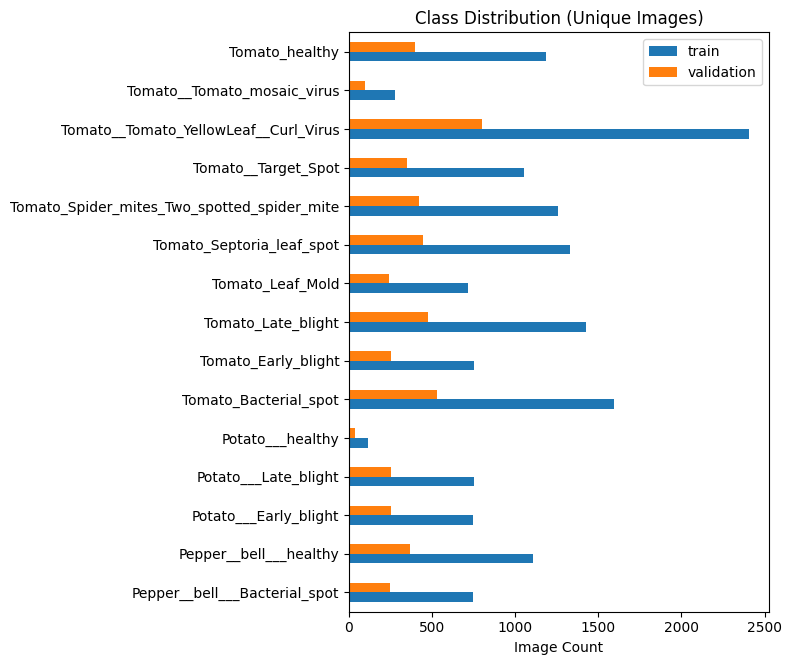

Imbalance ratio (largest / smallest train class): 21.3x


In [8]:
labels_all = np.array([y for p, y in ALL_ITEMS])
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(np.zeros(len(ALL_ITEMS)), labels_all, GROUPS))
TRAIN_ITEMS = [ALL_ITEMS[i] for i in tr_idx]
VAL_ITEMS = [ALL_ITEMS[i] for i in va_idx]

# ---- Leakage verification (three independent checks) ----
assert len(set(GROUPS[tr_idx]) & set(GROUPS[va_idx])) == 0, "A near-duplicate group straddles the split!"
assert len(set(HASH[p] for p, y in TRAIN_ITEMS) & set(HASH[p] for p, y in VAL_ITEMS)) == 0, "Exact duplicate across split!"
tr_set, va_set = set(tr_idx.tolist()), set(va_idx.tolist())
n_close = 0
for y, (idxs, H) in HSTORE.items():
    v_loc = [k for k, i in enumerate(idxs) if i in va_set]
    t_loc = [k for k, i in enumerate(idxs) if i in tr_set]
    if v_loc and t_loc:
        n_close += int((hamming_min_over_variants(H[v_loc, 0, :], H[t_loc]) <= NEAR_DUP_T).sum())
assert n_close == 0, f"{n_close} val/train pairs are within the near-duplicate threshold!"
print(f"Train pool: {len(TRAIN_ITEMS)} | Validation set: {len(VAL_ITEMS)} | exact-dup, group and cross-split hash checks: PASSED")

def count_per_class(items):
    return np.bincount([y for p, y in items], minlength=NC)

dist = pd.DataFrame({"train": count_per_class(TRAIN_ITEMS), "validation": count_per_class(VAL_ITEMS)}, index=CLASSES)
dist.plot.barh(figsize=(8, max(3, 0.35*NC + 1.5)), title="Class Distribution (Unique Images)")
plt.xlabel("Image Count"); plt.tight_layout()
plt.savefig(RESULTS / "class_distribution.png", dpi=150); plt.show()
print(f"Imbalance ratio (largest / smallest train class): {round(dist.train.max() / max(dist.train.min(), 1), 1)}x")

## 9. Domain-Specific Augmentation Pipeline
The functions live in `cropaugment.py` (Section 7). They map one-to-one onto the brief's three variation factors, plus a field-gap transform:
1. `change_lighting`: global brightness/contrast + polygon cast shadows + Gaussian specular glare.
2. `change_angle`: in-plane rotation (±40°), mirroring, affine shear.
3. `change_growth_stage`: young (smaller, yellow-green) vs. mature (zoomed, dark-green) leaf. **This is a proxy**: the dataset has no growth-stage labels, so it approximates the *appearance* change (scale + chlorophyll tint), not real phenology.
4. `composite_background`: segments the leaf from its studio background (colour distance from the border colour + morphology) and pastes it, at random scale/position, onto a procedural soil / grass / foliage background. This targets the lab-to-field gap directly. Segmentation failures (mask too small/large) fall back to a standard pipeline copy and are counted.

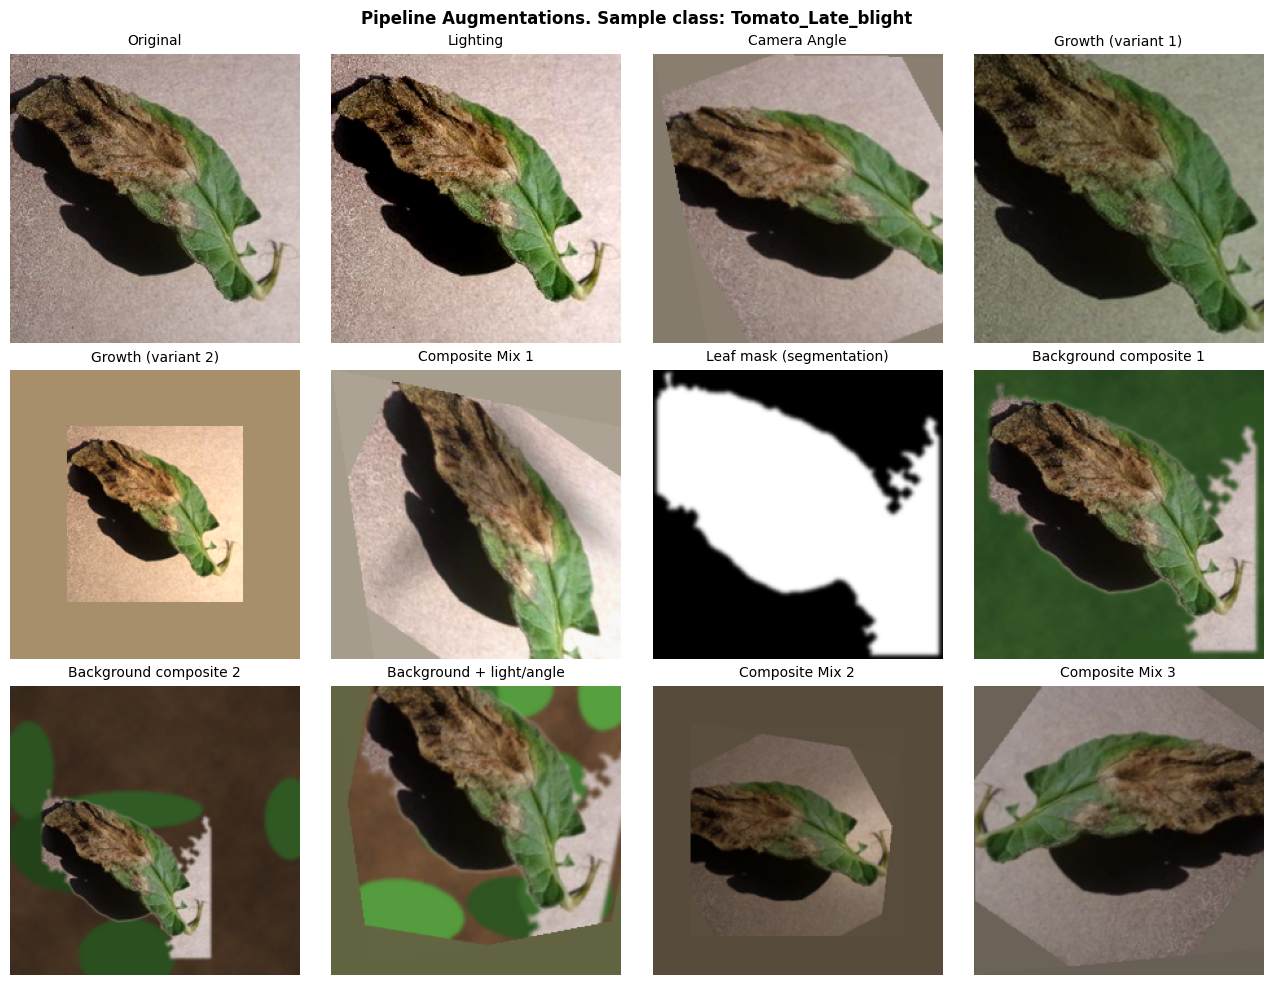

In [9]:
path0, label0 = random.Random(3).choice(VAL_ITEMS)
original = Image.open(path0).convert("RGB").resize((224, 224))
rng = random.Random(5)
mask0 = leaf_mask(original)

tiles = [("Original", original),
         ("Lighting", change_lighting(original, rng)),
         ("Camera Angle", change_angle(original, rng)),
         ("Growth (variant 1)", change_growth_stage(original, rng)),
         ("Growth (variant 2)", change_growth_stage(original, rng)),
         ("Composite Mix 1", augment_one(original, rng)[0]),
         ("Leaf mask (segmentation)", mask0 if mask0 is not None else Image.new("L", (224, 224), 0)),
         ("Background composite 1", composite_background(original, rng) or original),
         ("Background composite 2", composite_background(original, rng) or original),
         ("Background + light/angle", (augment_background(original, rng)[0] or original)),
         ("Composite Mix 2", augment_one(original, rng)[0]),
         ("Composite Mix 3", augment_one(original, rng)[0])]
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, (title, im) in zip(axes.flat, tiles):
    ax.imshow(im, cmap="gray" if im.mode == "L" else None)
    ax.set_title(title, fontsize=10); ax.axis("off")
plt.suptitle(f"Pipeline Augmentations. Sample class: {CLASSES[label0]}", fontweight="bold")
plt.tight_layout(); plt.savefig(RESULTS / "pipeline_examples.png", dpi=150); plt.show()

## 10. Simulate the Low-Data Regime (10 %) & Generate Augmented Datasets **per seed**
For every seed we sample a *different* 10 % subset of the training split (stratified, minimum 5 images per class) and generate `COPIES` domain-pipeline copies and `BG_COPIES` background-composited copies per source photo with a seed-specific RNG. This makes the multi-seed ± a genuine measure of data-sampling variability.

In [10]:
def take_fraction(items, fraction, seed):
    rng = random.Random(seed)
    chosen = []
    for c in range(NC):
        photos = [it for it in items if it[1] == c]
        n = min(max(5, round(len(photos) * fraction)), len(photos))
        chosen += rng.sample(photos, n)
    return chosen

LOW, PIPE, BGI = {}, {}, {}
for s in SEEDS:
    LOW[s] = take_fraction(TRAIN_ITEMS, LOW_FRAC, s)
    rng = random.Random(10_000 + s)
    PIPE[s], BGI[s] = [], []
    type_count, n_bg_fail = {}, 0
    for path, label in LOW[s]:
        original = Image.open(path).convert("RGB")
        stem = f"{Path(path).stem}_{HASH[path][:8]}"
        pf = PIPE_DIR / f"seed{s}" / CLASSES[label]; pf.mkdir(parents=True, exist_ok=True)
        for k in range(COPIES):
            new_img, kind = augment_one(original, rng)
            type_count[kind] = type_count.get(kind, 0) + 1
            sp = pf / f"{stem}_aug{k}.jpg"; new_img.save(sp, quality=95)
            PIPE[s].append((str(sp), label))
        bf = BG_DIR / f"seed{s}" / CLASSES[label]; bf.mkdir(parents=True, exist_ok=True)
        for k in range(BG_COPIES):
            new_img, kind = augment_background(original, rng)
            if new_img is None:                       # segmentation unreliable -> standard pipeline copy
                n_bg_fail += 1
                new_img, kind = augment_one(original, rng)
            sp = bf / f"{stem}_bg{k}.jpg"; new_img.save(sp, quality=95)
            BGI[s].append((str(sp), label))
    print(f"Seed {s}: low-data subset {len(LOW[s])} imgs ({100*len(LOW[s])/len(TRAIN_ITEMS):.1f}% of train) | "
          f"pipeline copies {len(PIPE[s])} | background copies {len(BGI[s])} "
          f"(segmentation fallback {n_bg_fail}/{len(BGI[s])} = {100*n_bg_fail/max(1,len(BGI[s])):.1f}%)")
    print("   transformation mix:", type_count)

LOW_ITEMS = LOW[SEEDS[0]]   # convenience handle for plots

Seed 0: low-data subset 1548 imgs (10.0% of train) | pipeline copies 6192 | background copies 3096 (segmentation fallback 0/3096 = 0.0%)
   transformation mix: {'growth+lighting': 977, 'lighting': 1072, 'lighting+angle': 1078, 'all': 991, 'growth': 1064, 'angle': 1010}
Seed 1: low-data subset 1548 imgs (10.0% of train) | pipeline copies 6192 | background copies 3096 (segmentation fallback 0/3096 = 0.0%)
   transformation mix: {'growth': 973, 'lighting+angle': 1022, 'all': 1054, 'angle': 1065, 'growth+lighting': 1050, 'lighting': 1028}
Seed 2: low-data subset 1548 imgs (10.0% of train) | pipeline copies 6192 | background copies 3096 (segmentation fallback 0/3096 = 0.0%)
   transformation mix: {'lighting+angle': 1049, 'all': 1028, 'angle': 1057, 'growth': 1045, 'lighting': 997, 'growth+lighting': 1016}


## 11. Robustness Stress-Test Benchmark
All models are tested on the same fixed, deterministic corruptions of held-out validation images. They **differ in implementation and strength** from the training transforms:

**In-family (interpolation):**
* `lighting`: non-linear gamma + directional side-lighting gradient.
* `angle`: ±45° rotation + full 4-point projective warp.
* `growth`: extreme growth-stage shifts (`strength` ∈ [0.6, 0.9]).
* `field mix`: lighting + perspective + growth combined.

**Out-of-distribution (never seen in any model's training):**
* `quality`: Gaussian blur + heavy JPEG compression.
* `color+noise`: white-balance shift (R/B gains) + Gaussian sensor noise.
* `occlusion`: 2-3 random opaque rectangles (fingers, other leaves, stems).
* `clutter`: the leaf is segmented and pasted onto a 2×2 mosaic of other real leaf photos (busy, leaf-textured background).

Clean validation set: 5157 | Stress-test subset per condition: 1000


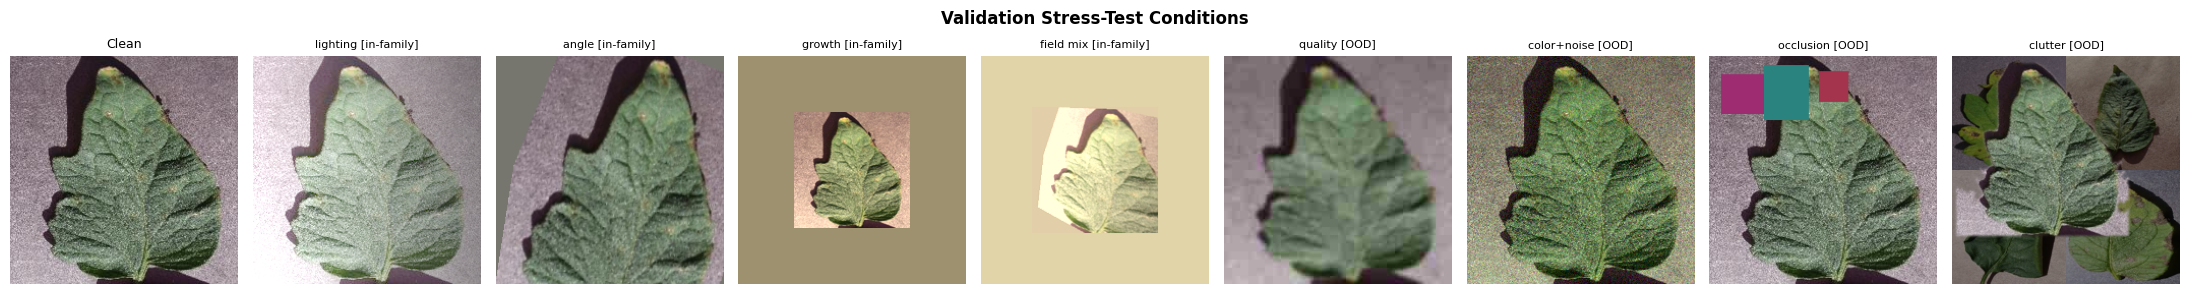

In [11]:
def test_lighting(img, rng):
    arr = np.asarray(img).astype(np.float32) / 255.0
    gamma = rng.choice([rng.uniform(0.4, 0.7), rng.uniform(1.5, 2.2)])
    arr = arr ** gamma
    h, w = arr.shape[:2]
    side = np.linspace(-1, 1, w)[None, :] * np.ones((h, 1))
    arr = arr * (1 + rng.uniform(0.3, 0.6) * rng.choice([-1, 1]) * side)[..., None]
    return Image.fromarray((np.clip(arr, 0, 1) * 255).astype(np.uint8))

def find_perspective_coeffs(src, dst):
    A, B = [], []
    for (x, y), (u, v) in zip(src, dst):
        A.append([x, y, 1, 0, 0, 0, -u*x, -u*y])
        A.append([0, 0, 0, x, y, 1, -v*x, -v*y])
        B.extend([u, v])
    return np.linalg.solve(np.array(A, dtype=float), np.array(B, dtype=float)).tolist()

def test_angle(img, rng):
    fill = avg_color(img)
    img = img.rotate(rng.uniform(-45, 45), resample=Image.BILINEAR, fillcolor=fill)
    w, h = img.size
    corners = [(0, 0), (w, 0), (w, h), (0, h)]
    moved = [(x + rng.uniform(-0.2, 0.2) * w, y + rng.uniform(-0.2, 0.2) * h) for x, y in corners]
    return img.transform((w, h), Image.PERSPECTIVE, find_perspective_coeffs(corners, moved), Image.BILINEAR, fillcolor=fill)

def test_growth(img, rng):
    return change_growth_stage(img, rng, strength=rng.uniform(0.6, 0.9))

def test_mix(img, rng):
    return test_growth(test_angle(test_lighting(img, rng), rng), rng)

def test_quality(img, rng):
    img = img.filter(ImageFilter.GaussianBlur(rng.uniform(1.0, 3.0)))
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=rng.randint(15, 40))
    buf.seek(0)
    return Image.open(buf).convert("RGB")

def test_color_noise(img, rng):
    arr = np.asarray(img).astype(np.float32) * np.array([rng.uniform(0.75, 1.3), 1.0, rng.uniform(0.7, 1.3)])
    nrng = np.random.default_rng(rng.randint(0, 2**31 - 1))
    arr = arr + nrng.normal(0, rng.uniform(10, 25), arr.shape)
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def test_occlusion(img, rng):
    img = img.copy(); d = ImageDraw.Draw(img); w, h = img.size
    for _ in range(rng.randint(2, 3)):
        bw, bh = int(w * rng.uniform(0.12, 0.25)), int(h * rng.uniform(0.12, 0.25))
        x, y = rng.randint(0, w - bw), rng.randint(0, h - bh)
        d.rectangle((x, y, x + bw, y + bh), fill=tuple(rng.randint(20, 220) for _ in range(3)))
    return img

def test_clutter(img, rng):
    bg = Image.new("RGB", (224, 224))
    for j in range(4):
        p, _ = VAL_ITEMS[rng.randint(0, len(VAL_ITEMS) - 1)]
        t = Image.open(p).convert("RGB").resize((112, 112))
        if rng.random() < 0.5:
            t = ImageOps.mirror(t)
        bg.paste(t, ((j % 2) * 112, (j // 2) * 112))
    bg = ImageEnhance.Brightness(bg).enhance(rng.uniform(0.6, 1.0))
    mask = leaf_mask(img)
    sw = int(224 * rng.uniform(0.65, 0.9))
    fg = img.resize((sw, sw))
    mk = mask.resize((sw, sw)) if mask is not None else Image.new("L", (sw, sw), 255)
    bg.paste(fg, (rng.randint(0, 224 - sw), rng.randint(0, 224 - sw)), mk)
    return bg

IN_FAMILY = ["lighting", "angle", "growth", "field mix"]
OOD = ["quality", "color+noise", "occlusion", "clutter"]
TEST_FUNCS = {"lighting": test_lighting, "angle": test_angle, "growth": test_growth, "field mix": test_mix,
              "quality": test_quality, "color+noise": test_color_noise, "occlusion": test_occlusion, "clutter": test_clutter}
TEST_IDS = {name: i + 1 for i, name in enumerate(TEST_FUNCS)}
CONDITIONS = ["clean"] + list(TEST_FUNCS.keys())

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
to_tensor = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])

class PhotoDataset(Dataset):
    def __init__(self, items, test_name=None):
        self.items = items
        self.test_name = test_name
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, label = self.items[i]
        img = Image.open(path).convert("RGB").resize((224, 224))
        if self.test_name is not None:
            rng = random.Random(1000003 * TEST_IDS[self.test_name] + i)
            img = TEST_FUNCS[self.test_name](img, rng)
        return to_tensor(img), label

if TEST_N >= len(VAL_ITEMS):
    TEST_ITEMS = VAL_ITEMS
else:
    TEST_ITEMS, _ = train_test_split(VAL_ITEMS, train_size=TEST_N, stratify=[y for p, y in VAL_ITEMS], random_state=SEED)
Y_COND = {c: np.array([y for p, y in (VAL_ITEMS if c == "clean" else TEST_ITEMS)]) for c in CONDITIONS}
print(f"Clean validation set: {len(VAL_ITEMS)} | Stress-test subset per condition: {len(TEST_ITEMS)}")

path1, label1 = random.Random(9).choice(VAL_ITEMS)
img1 = Image.open(path1).convert("RGB").resize((224, 224))
fig, axes = plt.subplots(1, 9, figsize=(22, 3.0))
axes[0].imshow(img1); axes[0].set_title("Clean", fontsize=9)
for ax, name in zip(axes[1:], TEST_FUNCS):
    ax.imshow(TEST_FUNCS[name](img1, random.Random(7)))
    ax.set_title(name + (" [in-family]" if name in IN_FAMILY else " [OOD]"), fontsize=8)
for ax in axes: ax.axis("off")
plt.suptitle("Validation Stress-Test Conditions", fontweight="bold")
plt.tight_layout(); plt.savefig(RESULTS / "test_conditions.png", dpi=150); plt.show()

## 12. Classifier Architecture & Training Harness
We fine-tune an ImageNet-pretrained **ResNet-18** with inverse-frequency class weights and cosine-annealed AdamW. Every model (A, A+, B, B2, C) performs exactly `SAMPLES_PER_EPOCH × EPOCHS` sampled image updates; only *what is in the pool* differs. For Model C the sampler up-weights the (few) diffusion images to a fixed share (`DIFF_SHARE`) of the draws so they are not diluted to ~2 % of the pool.

In [12]:
NAMES = {"A": "A: original only", "AP": "A+: standard aug", "B": "B: + pipeline",
         "BG": "B2: + pipeline + background", "C": "C: + pipeline + diffusion"}
MODEL_ORDER = ["A", "AP", "B", "BG", "C"]

def make_model():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, NC)
    return model.to(device)

aug_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.4, 0.4, 0.3, 0.05),
    transforms.ToTensor(), normalize])

class AugDataset(Dataset):
    """Standard torchvision augmentation (control baseline A+)."""
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return aug_tf(Image.open(p).convert("RGB")), y

def train_model(items, seed, name="", dataset_cls=None, sample_weights=None):
    set_seed(seed)
    model = make_model()
    data = (dataset_cls or PhotoDataset)(items)
    g = torch.Generator().manual_seed(seed)
    if sample_weights is None:
        sampler = RandomSampler(data, replacement=True, num_samples=SAMPLES_PER_EPOCH, generator=g)
    else:
        sampler = WeightedRandomSampler(torch.as_tensor(sample_weights, dtype=torch.double),
                                        num_samples=SAMPLES_PER_EPOCH, replacement=True, generator=g)
    loader = DataLoader(data, batch_size=BATCH, sampler=sampler, drop_last=True,
                        num_workers=2 if os.name != "nt" else 0, pin_memory=(device == "cuda"))
    counts = np.bincount([y for p, y in items], minlength=NC).clip(min=1)
    weights = torch.tensor(len(items) / (NC * counts), dtype=torch.float32).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    for epoch in range(EPOCHS):
        model.train()
        correct, total = 0, 0
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            out = model(x)
            loss = loss_fn(out, y)
            loss.backward()
            optimizer.step()
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
        scheduler.step()
    print(f"  Model {name} | Seed {seed} | Pool size: {len(items)} | Final-epoch train acc: {100*correct/total:.1f}%")
    return model

def get_probabilities(model, items, test_name=None):
    model.eval()
    all_probs = []
    loader = DataLoader(PhotoDataset(items, test_name), batch_size=64,
                        num_workers=2 if os.name != "nt" else 0, pin_memory=(device == "cuda"))
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device, non_blocking=True))
            all_probs.append(torch.softmax(out, 1).cpu().numpy())
    return np.concatenate(all_probs)

ROWS, PRED = [], {}          # PRED[(model_key, seed, condition)] -> predicted labels (reused by bootstrap, Q3, etc.)

def evaluate(model, key, seed):
    for cond in CONDITIONS:
        items, test_name = (VAL_ITEMS, None) if cond == "clean" else (TEST_ITEMS, cond)
        y_true = Y_COND[cond]
        y_pred = get_probabilities(model, items, test_name).argmax(1)
        PRED[(key, seed, cond)] = y_pred
        acc = float((y_true == y_pred).mean())
        f1 = float(f1_score(y_true, y_pred, average="macro", labels=list(range(NC)), zero_division=0))
        ROWS.append({"model": NAMES[key], "key": key, "seed": seed, "test": cond, "accuracy": acc, "f1": f1})
    last = ROWS[-len(CONDITIONS):]
    print("   -> " + " | ".join(f"{r['test']}: {100*r['accuracy']:.1f}%" for r in last))

MODELS = {}

## 13. Model A: Baseline (original 10 % only)

In [13]:
print("Training Model A (baseline)...")
for s in SEEDS:
    MODELS[("A", s)] = train_model(LOW[s], s, "A")
    evaluate(MODELS[("A", s)], "A", s)

Training Model A (baseline)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


  Model A | Seed 0 | Pool size: 1548 | Final-epoch train acc: 100.0%
   -> clean: 96.8% | lighting: 90.4% | angle: 75.0% | growth: 54.3% | field mix: 29.4% | quality: 48.9% | color+noise: 38.5% | occlusion: 93.4% | clutter: 44.9%
  Model A | Seed 1 | Pool size: 1548 | Final-epoch train acc: 100.0%
   -> clean: 96.9% | lighting: 88.4% | angle: 83.4% | growth: 54.6% | field mix: 35.0% | quality: 55.0% | color+noise: 47.3% | occlusion: 93.4% | clutter: 54.3%
  Model A | Seed 2 | Pool size: 1548 | Final-epoch train acc: 100.0%
   -> clean: 96.5% | lighting: 91.2% | angle: 79.5% | growth: 50.0% | field mix: 23.4% | quality: 48.7% | color+noise: 43.0% | occlusion: 92.6% | clutter: 46.8%


### Model A+: Standard torchvision augmentation (control)
*Ensures any gain of the domain pipeline is not just "generic augmentation helps". Same data, budget and seeds as A; transforms: RandomResizedCrop, flip, rotation ±30°, ColorJitter.*

In [14]:
print("Training Model A+ (standard augmentation, original 10% only)...")
for s in SEEDS:
    MODELS[("AP", s)] = train_model(LOW[s], s, "A+", dataset_cls=AugDataset)
    evaluate(MODELS[("AP", s)], "AP", s)

Training Model A+ (standard augmentation, original 10% only)...
  Model A+ | Seed 0 | Pool size: 1548 | Final-epoch train acc: 99.0%
   -> clean: 91.8% | lighting: 90.3% | angle: 93.3% | growth: 66.8% | field mix: 48.5% | quality: 52.6% | color+noise: 46.9% | occlusion: 87.4% | clutter: 56.0%
  Model A+ | Seed 1 | Pool size: 1548 | Final-epoch train acc: 98.6%
   -> clean: 93.8% | lighting: 91.4% | angle: 92.8% | growth: 72.4% | field mix: 56.1% | quality: 65.6% | color+noise: 59.0% | occlusion: 90.4% | clutter: 60.4%
  Model A+ | Seed 2 | Pool size: 1548 | Final-epoch train acc: 98.8%
   -> clean: 94.0% | lighting: 89.6% | angle: 92.8% | growth: 68.9% | field mix: 54.4% | quality: 63.4% | color+noise: 42.4% | occlusion: 89.4% | clutter: 58.3%


## 14. Model B: original + domain-pipeline augmentations

In [15]:
print("Training Model B (original + domain pipeline)...")
for s in SEEDS:
    MODELS[("B", s)] = train_model(LOW[s] + PIPE[s], s, "B")
    evaluate(MODELS[("B", s)], "B", s)

Training Model B (original + domain pipeline)...
  Model B | Seed 0 | Pool size: 7740 | Final-epoch train acc: 99.5%
   -> clean: 96.8% | lighting: 94.4% | angle: 94.9% | growth: 87.8% | field mix: 74.4% | quality: 67.8% | color+noise: 44.5% | occlusion: 93.4% | clutter: 49.0%
  Model B | Seed 1 | Pool size: 7740 | Final-epoch train acc: 99.5%
   -> clean: 96.5% | lighting: 93.2% | angle: 94.3% | growth: 90.9% | field mix: 75.7% | quality: 76.4% | color+noise: 63.3% | occlusion: 93.8% | clutter: 51.0%
  Model B | Seed 2 | Pool size: 7740 | Final-epoch train acc: 99.8%
   -> clean: 96.5% | lighting: 94.7% | angle: 95.5% | growth: 89.5% | field mix: 75.3% | quality: 67.2% | color+noise: 55.6% | occlusion: 94.1% | clutter: 52.1%


### Model B2: B + background-composited copies (lab → field-like clutter)

In [16]:
print("Training Model B2 (pipeline + background compositing)...")
for s in SEEDS:
    MODELS[("BG", s)] = train_model(LOW[s] + PIPE[s] + BGI[s], s, "B2")
    evaluate(MODELS[("BG", s)], "BG", s)

Training Model B2 (pipeline + background compositing)...
  Model B2 | Seed 0 | Pool size: 10836 | Final-epoch train acc: 98.9%
   -> clean: 96.7% | lighting: 93.5% | angle: 94.9% | growth: 89.1% | field mix: 74.5% | quality: 69.5% | color+noise: 58.5% | occlusion: 94.1% | clutter: 53.7%
  Model B2 | Seed 1 | Pool size: 10836 | Final-epoch train acc: 99.1%
   -> clean: 96.6% | lighting: 93.3% | angle: 94.3% | growth: 89.6% | field mix: 76.3% | quality: 72.2% | color+noise: 53.7% | occlusion: 93.7% | clutter: 57.0%
  Model B2 | Seed 2 | Pool size: 10836 | Final-epoch train acc: 99.2%
   -> clean: 96.8% | lighting: 94.4% | angle: 95.0% | growth: 88.4% | field mix: 73.1% | quality: 66.2% | color+noise: 58.0% | occlusion: 93.6% | clutter: 55.4%


## 15. Generative AI: Stable Diffusion Img2Img + Semantic-Consistency Filter
We use `CompVis/stable-diffusion-v1-4` (`StableDiffusionImg2ImgPipeline`, `strength=0.35`) to synthesise natural lighting/background variation from each seed's 10 % subset.

**Preventing label corruption (confidence gate):** diffusion can smooth away small lesions. Every generated image is scored by **that seed's Model A**; it is accepted only if Model A predicts the ground-truth class with confidence ≥ `FILTER_CONF`. (Caveat: this makes the gate classifier-biased, discussed in Limitations.)

In [17]:
DIFFUSION_READY = False
pipe = None
try:
    from diffusers import StableDiffusionImg2ImgPipeline
    pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
        "CompVis/stable-diffusion-v1-4",
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
        use_safetensors=True
    ).to(device)
    pipe.enable_attention_slicing()
    pipe.safety_checker = None
    pipe.requires_safety_checker = False
    pipe.set_progress_bar_config(disable=True)
    DIFFUSION_READY = True
    print("Stable Diffusion v1.4 Img2Img pipeline loaded successfully.")
except Exception as e:
    print("Stable Diffusion could not be loaded:", e)
    print("Model C will be skipped. Ensure a T4 GPU runtime and internet access are active.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion v1.4 Img2Img pipeline loaded successfully.


In [18]:
VARIATIONS = [
    "harsh midday sunlight, hard cast shadows",
    "overcast sky, soft diffuse light",
    "late afternoon warm side light, slightly different camera distance",
    "outdoor soil and mulch background, natural daylight"
]
NEGATIVE = "cartoon, illustration, text, watermark, deformed, duplicate, blur"

def class_name_to_words(name):
    return " ".join(name.replace("_", " ").split())

CANDS = pd.DataFrame()
ACCEPTED = {s: [] for s in SEEDS}
THRESH = {s: FILTER_CONF for s in SEEDS}

if DIFFUSION_READY:
    records = []
    for s in SEEDS:
        for c in range(NC):
            photos = [it for it in LOW[s] if it[1] == c]
            out_dir = DIFF_DIR / f"seed{s}" / CLASSES[c]; out_dir.mkdir(parents=True, exist_ok=True)
            for i in range(DIFF_PER_CLASS):
                src_path = photos[i % len(photos)][0]
                init_image = ImageOps.fit(Image.open(src_path).convert("RGB"), (512, 512))
                prompt = f"photo of a {class_name_to_words(CLASSES[c])} leaf, {VARIATIONS[i % 4]}, realistic, natural texture"
                gen = torch.Generator(device=device).manual_seed(SEED + 1000*c + i + 100000*s)
                result = pipe(prompt=prompt, negative_prompt=NEGATIVE, image=init_image,
                              strength=DIFF_STRENGTH, num_inference_steps=DIFF_STEPS,
                              guidance_scale=7.5, generator=gen).images[0]
                save_path = out_dir / f"diff_{i:03d}.jpg"
                result.save(save_path, quality=95)
                records.append({"seed": s, "path": str(save_path), "label": c, "src": src_path})
        print(f"Seed {s}: generated {sum(r['seed'] == s for r in records)} candidate images")

    # Semantic-consistency gate: each seed is scored by its OWN Model A
    CANDS = pd.DataFrame(records)
    CANDS["class"] = CANDS["label"].map(lambda i: CLASSES[i])
    CANDS["pred"], CANDS["conf"] = 0, 0.0
    for s in SEEDS:
        m = CANDS.seed == s
        probs = get_probabilities(MODELS[("A", s)], list(zip(CANDS.loc[m, "path"], CANDS.loc[m, "label"])))
        CANDS.loc[m, "pred"] = probs.argmax(1)
        CANDS.loc[m, "conf"] = probs.max(1)
    CANDS["accepted"] = False
    for s in SEEDS:
        m = CANDS.seed == s
        ok = (CANDS.pred == CANDS.label) & (CANDS.conf >= FILTER_CONF) & m
        if ok.sum() < MIN_ACCEPTED_TOTAL:
            THRESH[s] = 0.65
            ok = (CANDS.pred == CANDS.label) & (CANDS.conf >= 0.65) & m
            print(f"NOTICE (seed {s}): too few images passed at {FILTER_CONF}; threshold lowered to 0.65. Mention in the report.")
        CANDS.loc[ok, "accepted"] = True
        ACCEPTED[s] = [(r.path, r.label) for r in CANDS[ok].itertuples()]

    CANDS.to_csv(RESULTS / "diffusion_log.csv", index=False)
    print(f"\nTotal generated: {len(CANDS)} | Accepted: {int(CANDS.accepted.sum())} ({100*CANDS.accepted.mean():.1f}%)")
    print("Accepted per seed:", {s: len(ACCEPTED[s]) for s in SEEDS}, "| thresholds:", THRESH)
    print("\nAcceptance rate (%) per class (all seeds pooled):")
    print((CANDS.groupby("class").accepted.mean() * 100).round(1).to_string())

    del pipe
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Seed 0: generated 225 candidate images
Seed 1: generated 225 candidate images
Seed 2: generated 225 candidate images

Total generated: 675 | Accepted: 464 (68.7%)
Accepted per seed: {0: 164, 1: 146, 2: 154} | thresholds: {0: 0.8, 1: 0.8, 2: 0.8}

Acceptance rate (%) per class (all seeds pooled):
class
Pepper__bell___Bacterial_spot                   84.4
Pepper__bell___healthy                          71.1
Potato___Early_blight                          100.0
Potato___Late_blight                            71.1
Potato___healthy                                77.8
Tomato_Bacterial_spot                           57.8
Tomato_Early_blight                             93.3
Tomato_Late_blight                              53.3
Tomato_Leaf_Mold                                33.3
Tomato_Septoria_leaf_spot                       86.7
Tomato_Spider_mites_Two_spotted_spider_mite     17.8
Tomato__Target_Spot                             15.6
Tomato__Tomato_YellowLeaf__Curl_Virus           91.1
Tomato__

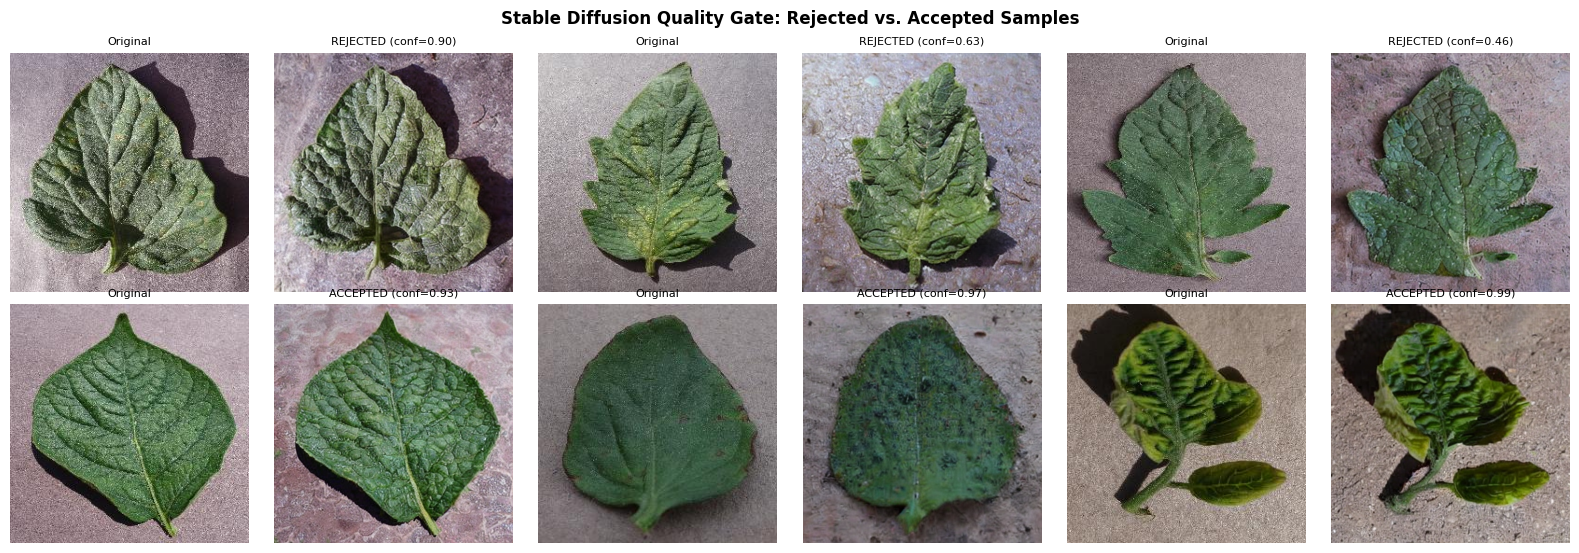

In [19]:
# Visualise accepted vs. rejected diffusion samples
if len(CANDS) > 0:
    rejected, accepted = CANDS[~CANDS.accepted], CANDS[CANDS.accepted]
    fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
    for r, (tag, df) in enumerate([("REJECTED", rejected), ("ACCEPTED", accepted)]):
        if len(df) == 0:
            axes[r, 0].set_title(f"No {tag} images", fontsize=9)
            continue
        for c, row in enumerate(df.sample(min(3, len(df)), random_state=1).itertuples()):
            axes[r, 2*c].imshow(Image.open(row.src).convert("RGB")); axes[r, 2*c].set_title("Original", fontsize=8)
            axes[r, 2*c+1].imshow(Image.open(row.path)); axes[r, 2*c+1].set_title(f"{tag} (conf={row.conf:.2f})", fontsize=8)
    for ax in axes.flat: ax.axis("off")
    plt.suptitle("Stable Diffusion Quality Gate: Rejected vs. Accepted Samples", fontweight="bold")
    plt.tight_layout(); plt.savefig(RESULTS / "accepted_vs_rejected.png", dpi=150); plt.show()

## 16. Model C: original + domain pipeline + filtered diffusion
Each seed trains on its own pool (`LOW + PIPE + accepted diffusion`). Accepted diffusion images are sampled so that they make up `DIFF_SHARE` of the draws (same total number of updates as every other model).

In [20]:
def diffusion_weights(n_base, n_diff, share):
    w = np.ones(n_base + n_diff)
    w[n_base:] = (share / (1 - share)) * n_base / n_diff
    return w

if any(len(ACCEPTED[s]) > 0 for s in SEEDS):
    print("Training Model C (pipeline + filtered diffusion)...")
    for s in SEEDS:
        if len(ACCEPTED[s]) == 0:
            print(f"  seed {s}: no accepted images, skipped"); continue
        base = LOW[s] + PIPE[s]
        w = diffusion_weights(len(base), len(ACCEPTED[s]), DIFF_SHARE)
        MODELS[("C", s)] = train_model(base + ACCEPTED[s], s, "C", sample_weights=w)
        evaluate(MODELS[("C", s)], "C", s)
else:
    print("No accepted Stable Diffusion images available; Model C skipped.")

Training Model C (pipeline + filtered diffusion)...
  Model C | Seed 0 | Pool size: 7904 | Final-epoch train acc: 99.6%
   -> clean: 96.9% | lighting: 92.6% | angle: 94.6% | growth: 90.3% | field mix: 75.3% | quality: 71.6% | color+noise: 67.9% | occlusion: 93.1% | clutter: 53.6%
  Model C | Seed 1 | Pool size: 7886 | Final-epoch train acc: 99.6%
   -> clean: 96.7% | lighting: 94.2% | angle: 94.8% | growth: 91.3% | field mix: 75.2% | quality: 75.1% | color+noise: 72.8% | occlusion: 94.1% | clutter: 53.5%
  Model C | Seed 2 | Pool size: 7894 | Final-epoch train acc: 99.8%
   -> clean: 96.8% | lighting: 93.7% | angle: 94.8% | growth: 88.9% | field mix: 73.2% | quality: 71.6% | color+noise: 76.4% | occlusion: 92.9% | clutter: 51.6%


## 17. Quantitative Results & Robustness Comparison

Accuracy % (mean ± std across 3 seeds). In-family: ['lighting', 'angle', 'growth', 'field mix'] | OOD: ['quality', 'color+noise', 'occlusion', 'clutter']


test,clean,lighting,angle,growth,field mix,quality,color+noise,occlusion,clutter
model,,,,,,,,,
A: original only,96.7 ± 0.2,90.0 ± 1.4,79.3 ± 4.2,53.0 ± 2.6,29.3 ± 5.8,50.9 ± 3.6,42.9 ± 4.4,93.1 ± 0.5,48.7 ± 5.0
A+: standard aug,93.2 ± 1.2,90.4 ± 0.9,93.0 ± 0.3,69.4 ± 2.8,53.0 ± 4.0,60.5 ± 7.0,49.4 ± 8.6,89.1 ± 1.5,58.2 ± 2.2
B: + pipeline,96.6 ± 0.1,94.1 ± 0.8,94.9 ± 0.6,89.4 ± 1.6,75.1 ± 0.7,70.5 ± 5.1,54.5 ± 9.5,93.8 ± 0.4,50.7 ± 1.6
B2: + pipeline + background,96.7 ± 0.1,93.7 ± 0.6,94.7 ± 0.4,89.0 ± 0.6,74.6 ± 1.6,69.3 ± 3.0,56.7 ± 2.6,93.8 ± 0.3,55.4 ± 1.7
C: + pipeline + diffusion,96.8 ± 0.1,93.5 ± 0.8,94.7 ± 0.1,90.2 ± 1.2,74.6 ± 1.2,72.8 ± 2.0,72.4 ± 4.3,93.4 ± 0.6,52.9 ± 1.1



Grouped summary (mean accuracy %):


,clean,mean in-family,mean OOD
model,,,
A: original only,96.7,62.9,58.9
A+: standard aug,93.2,76.4,64.3
B: + pipeline,96.6,88.4,67.4
B2: + pipeline + background,96.7,88.0,68.8
C: + pipeline + diffusion,96.8,88.2,72.8



Macro F1 % (mean across seeds):


test,clean,lighting,angle,growth,field mix,quality,color+noise,occlusion,clutter
model,,,,,,,,,
A: original only,96.3,89.1,78.5,53.9,26.3,47.2,44.9,92.8,45.5
A+: standard aug,92.6,88.8,92.5,70.2,53.3,54.4,46.5,88.5,53.8
B: + pipeline,96.2,92.7,94.2,88.5,73.7,68.2,55.2,93.1,48.3
B2: + pipeline + background,96.5,93.3,94.3,88.5,73.0,66.8,55.3,93.5,53.2
C: + pipeline + diffusion,96.7,92.4,94.4,89.3,72.9,71.3,72.4,93.0,51.5


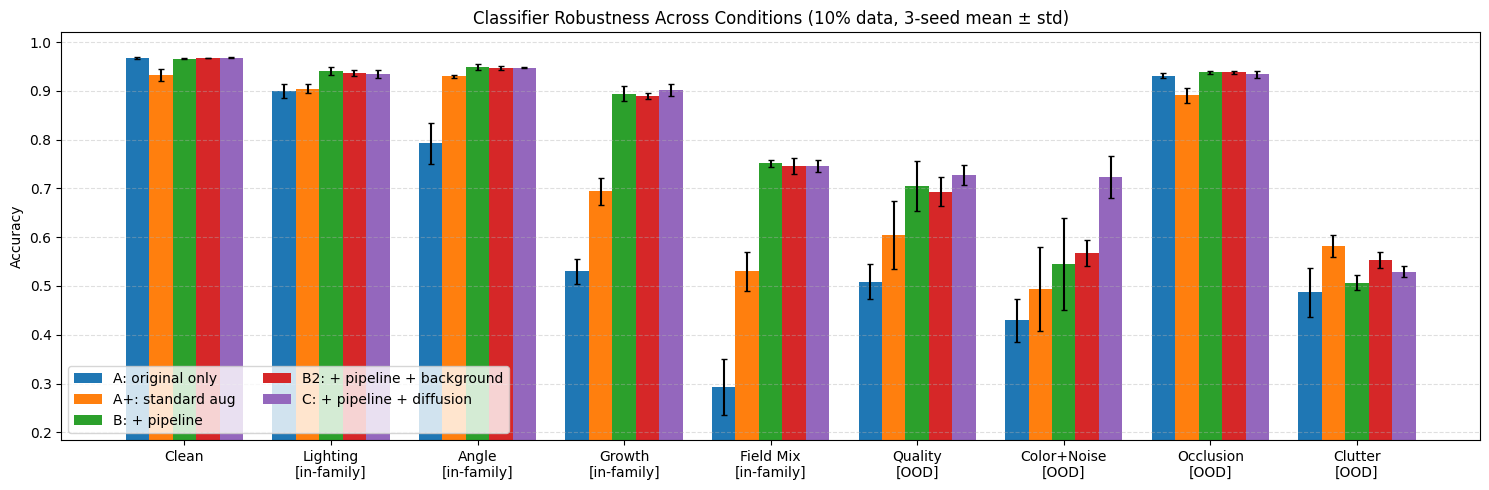

In [21]:
KEYS_TRAINED = [k for k in MODEL_ORDER if all((k, s) in MODELS for s in SEEDS)]
DF = pd.DataFrame(ROWS)
DF.to_csv(RESULTS / "all_runs.csv", index=False)
model_names = [NAMES[k] for k in KEYS_TRAINED]

mean_table = DF.groupby(["model", "test"]).accuracy.mean().unstack()[CONDITIONS].loc[model_names] * 100
std_table = DF.groupby(["model", "test"]).accuracy.std().unstack()[CONDITIONS].loc[model_names].fillna(0) * 100
table = mean_table.round(1).astype(str) + " ± " + std_table.round(1).astype(str)
print(f"Accuracy % (mean ± std across {len(SEEDS)} seeds). In-family: {IN_FAMILY} | OOD: {OOD}")
display(table)
table.to_csv(RESULTS / "table_accuracy.csv")

summ = pd.DataFrame({"clean": mean_table["clean"],
                     "mean in-family": mean_table[IN_FAMILY].mean(axis=1),
                     "mean OOD": mean_table[OOD].mean(axis=1)}).round(1)
print("\nGrouped summary (mean accuracy %):")
display(summ); summ.to_csv(RESULTS / "table_grouped_summary.csv")

f1_table = (DF.groupby(["model", "test"]).f1.mean().unstack()[CONDITIONS].loc[model_names] * 100).round(1)
print("\nMacro F1 % (mean across seeds):")
display(f1_table); f1_table.to_csv(RESULTS / "table_f1.csv")

fig, ax = plt.subplots(figsize=(15, 5))
width = 0.8 / len(model_names)
for i, name in enumerate(model_names):
    ax.bar(np.arange(len(CONDITIONS)) + i*width, mean_table.loc[name] / 100, width,
           yerr=std_table.loc[name] / 100, capsize=2, label=name)
ax.set_xticks(np.arange(len(CONDITIONS)) + width * (len(model_names) - 1) / 2)
ax.set_xticklabels([c.title() + ("\n[in-family]" if c in IN_FAMILY else "\n[OOD]" if c in OOD else "") for c in CONDITIONS])
ax.set_ylabel("Accuracy"); ax.set_ylim(max(0, DF.accuracy.min() - 0.05), 1.02)
ax.set_title(f"Classifier Robustness Across Conditions (10% data, {len(SEEDS)}-seed mean ± std)")
ax.legend(ncol=2); ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.savefig(RESULTS / "robustness_comparison.png", dpi=150); plt.show()

### Q3: Minority-class recall
Macro accuracy can hide failures on rare diseases. We report per-class recall (mean over seeds) for the **4 rarest classes** of the training split, with the number of validation images behind each recall, plus their mean. Small validation counts mean individual cells are noisy; read the *mean* column and consistency across conditions.

In [22]:
small_classes = [int(c) for c in np.argsort(count_per_class(TRAIN_ITEMS))[:min(4, NC)]]

def class_recall(key, cond, c):
    y = Y_COND[cond]; m = (y == c)
    return float(np.mean([(PRED[(key, s, cond)][m] == c).mean() for s in SEEDS])), int(m.sum())

Q3_CONDS = ["clean", "growth", "field mix", "quality", "occlusion", "clutter"]
rows = []
for key in KEYS_TRAINED:
    for cond in Q3_CONDS:
        row = {"model": NAMES[key], "test": cond}
        rec = []
        for c in small_classes:
            r, nv = class_recall(key, cond, c)
            rec.append(r)
            row[f"{CLASSES[c][:22]} (val n={nv})"] = f"{100*r:.0f}%"
        row["MEAN of 4 rare classes"] = f"{100*np.mean(rec):.0f}%"
        rows.append(row)
SMALL = pd.DataFrame(rows)
print("Rare classes:", [CLASSES[c] for c in small_classes], "| train-split sizes:", [int(count_per_class(TRAIN_ITEMS)[c]) for c in small_classes])
display(SMALL)
SMALL.to_csv(RESULTS / "small_class_recall.csv", index=False)

def minority_mean(key, cond):
    return float(np.mean([class_recall(key, cond, c)[0] for c in small_classes]))

Rare classes: ['Potato___healthy', 'Tomato__Tomato_mosaic_virus', 'Tomato_Leaf_Mold', 'Pepper__bell___Bacterial_spot'] | train-split sizes: [113, 279, 713, 748]


,model,test,Potato___healthy (val n=39),Tomato__Tomato_mosaic_ (val n=94),Tomato_Leaf_Mold (val n=239),Pepper__bell___Bacteri (val n=249),MEAN of 4 rare classes,Potato___healthy (val n=8),Tomato__Tomato_mosaic_ (val n=18),Tomato_Leaf_Mold (val n=46),Pepper__bell___Bacteri (val n=48)
0,A: original only,clean,96%,100%,97%,99%,98%,NaN,NaN,NaN,NaN
1,A: original only,growth,NaN,NaN,NaN,NaN,48%,50%,37%,46%,60%
2,A: original only,field mix,NaN,NaN,NaN,NaN,28%,67%,7%,16%,23%
3,A: original only,quality,NaN,NaN,NaN,NaN,52%,46%,59%,54%,49%
4,A: original only,occlusion,NaN,NaN,NaN,NaN,97%,100%,96%,96%,97%
5,A: original only,clutter,NaN,NaN,NaN,NaN,39%,29%,2%,34%,90%
6,A+: standard aug,clean,97%,99%,88%,98%,96%,NaN,NaN,NaN,NaN
7,A+: standard aug,growth,NaN,NaN,NaN,NaN,71%,75%,67%,62%,81%
8,A+: standard aug,field mix,NaN,NaN,NaN,NaN,52%,88%,31%,46%,43%
9,A+: standard aug,quality,NaN,NaN,NaN,NaN,56%,8%,81%,72%,60%


### Q4: Zero-shot transfer to real outdoor field photos (PlantDoc)
We evaluate all models on **PlantDoc** (CC-BY-4.0), real photographs taken in uncontrolled outdoor environments. None were seen in training.

* PlantDoc class names differ from PlantVillage names, so hand-written rules match them. **Only classes that map to exactly one class in both datasets are used**; matches are printed so they can be checked (fix any wrong one in `MANUAL_MAP`).
* Besides the plain all-class accuracy we also report a **restricted** accuracy where the argmax is taken only over the matched classes (a fairer number, since the test set only contains those).
* Accuracy on field photos is expected to be **far lower** than on clean lab photos. What matters is whether B / B2 / C beat A and A+, and by how much. PlantDoc is small and noisily labelled, so this is a supplementary real-world check, not a full proof.

Cloning PlantDoc real-field test dataset...
                      PlantDoc Class                       Matched Dataset Class  Photos
                     Apple Scab Leaf                 (no unique match - skipped)       0
                          Apple leaf                 (no unique match - skipped)       0
                     Apple rust leaf                 (no unique match - skipped)       0
               Bell_pepper leaf spot               Pepper__bell___Bacterial_spot      60
                    Bell_pepper leaf                      Pepper__bell___healthy      60
                      Blueberry leaf                 (no unique match - skipped)       0
                         Cherry leaf                 (no unique match - skipped)       0
                 Corn Gray leaf spot                 (no unique match - skipped)       0
                    Corn leaf blight                 (no unique match - skipped)       0
                      Corn rust leaf                 (no unique ma

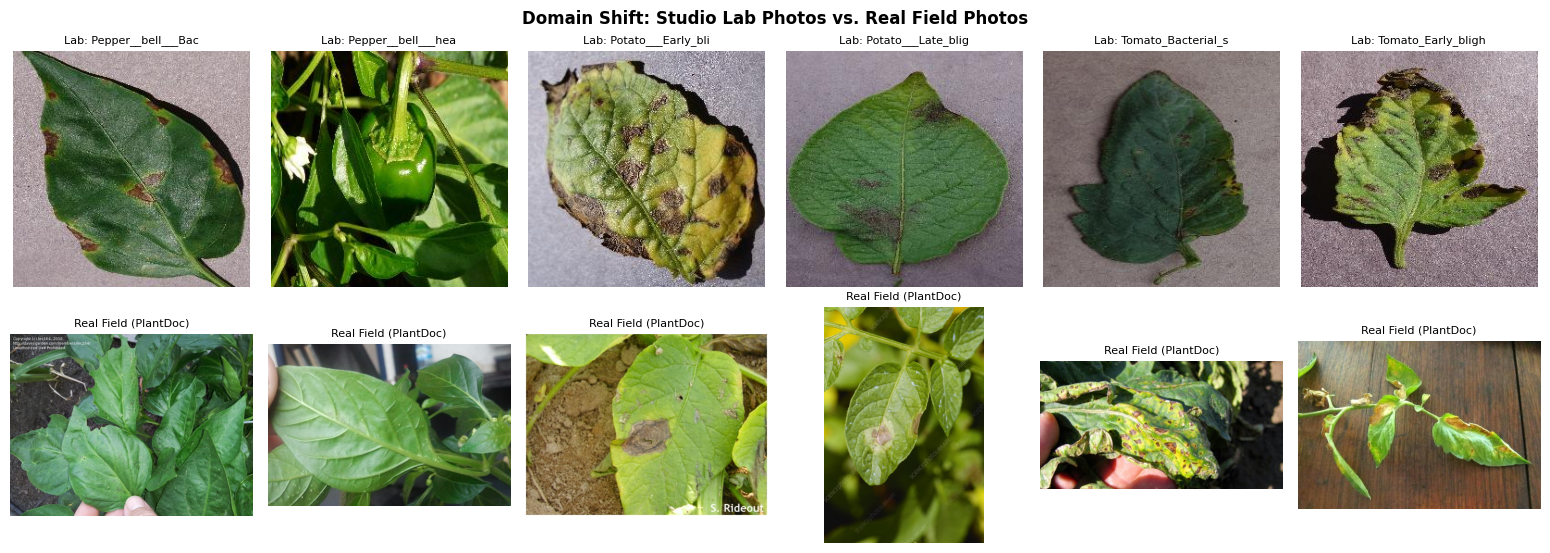

In [23]:
USE_FIELD_TEST = True
FIELD_DIR = BASE / "plantdoc"
MANUAL_MAP = {}

PLANTDOC_RULES = {
    "Apple Scab Leaf": ("apple", "scab"), "Apple leaf": ("apple", "healthy"), "Apple rust leaf": ("apple", "rust"),
    "Bell_pepper leaf spot": ("pepper", "bacterial"), "Bell_pepper leaf": ("pepper", "healthy"),
    "Blueberry leaf": ("blueberry", "healthy"), "Cherry leaf": ("cherry", "healthy"),
    "Corn Gray leaf spot": ("corn", "gray"), "Corn leaf blight": ("corn", "blight"), "Corn rust leaf": ("corn", "rust"),
    "Peach leaf": ("peach", "healthy"), "Potato leaf early blight": ("potato", "early"),
    "Potato leaf late blight": ("potato", "late"), "Raspberry leaf": ("raspberry", "healthy"),
    "Soyabean leaf": ("soy", "healthy"), "Squash Powdery mildew leaf": ("squash", "powdery"),
    "Strawberry leaf": ("strawberry", "healthy"), "Tomato Early blight leaf": ("tomato", "early"),
    "Tomato Septoria leaf spot": ("tomato", "septoria"), "Tomato leaf bacterial spot": ("tomato", "bacterial"),
    "Tomato leaf late blight": ("tomato", "late"), "Tomato leaf mosaic virus": ("tomato", "mosaic"),
    "Tomato leaf yellow virus": ("tomato", "yellow"), "Tomato leaf": ("tomato", "healthy"),
    "Tomato mold leaf": ("tomato", "mold"), "Tomato two spotted spider mites leaf": ("tomato", "spider"),
    "grape leaf black rot": ("grape", "rot"), "grape leaf": ("grape", "healthy"),
}

def name_words(name):
    return re.sub(r"[^a-z0-9]+", " ", name.lower()).split()

def find_match(plantdoc_name):
    plant, word = PLANTDOC_RULES[plantdoc_name]
    return [c for c in CLASSES if any(w.startswith(plant) for w in name_words(c)) and (word in name_words(c))]

if USE_FIELD_TEST and not FIELD_DIR.exists():
    print("Cloning PlantDoc real-field test dataset...")
    result = subprocess.run(["git", "clone", "-q", "--depth", "1",
                             "https://github.com/pratikkayal/PlantDoc-Dataset.git", str(FIELD_DIR)])
    if result.returncode != 0:
        print("Download failed; skipping field test.")

FIELD_ITEMS, rows = [], []
if USE_FIELD_TEST and FIELD_DIR.exists():
    for pd_name in PLANTDOC_RULES:
        matches = [MANUAL_MAP[pd_name]] if pd_name in MANUAL_MAP else find_match(pd_name)
        if len(matches) != 1:
            rows.append([pd_name, "(no unique match - skipped)", 0]); continue
        photos = []
        for split in ["train", "test"]:
            folder = FIELD_DIR / split / pd_name
            if folder.exists():
                photos += [f for f in sorted(folder.iterdir()) if f.suffix.lower() in EXTS]
        if len(photos) > FIELD_MAX_PER_CLASS:
            photos = random.Random(SEED).sample(photos, FIELD_MAX_PER_CLASS)
        for f in photos:
            FIELD_ITEMS.append((str(f), class_to_idx[matches[0]]))
        rows.append([pd_name, matches[0], len(photos)])
    print(pd.DataFrame(rows, columns=["PlantDoc Class", "Matched Dataset Class", "Photos"]).to_string(index=False))

field_classes = sorted(set(y for p, y in FIELD_ITEMS))
print(f"\nMatched real-field photos: {len(FIELD_ITEMS)} across {len(field_classes)}/{NC} classes")

if len(FIELD_ITEMS) == 0:
    print("No overlapping field classes found (expected with the synthetic demo dataset). Skipping Q4.")
else:
    shown = field_classes[:6]
    fig, axes = plt.subplots(2, len(shown), figsize=(2.6 * len(shown), 5.6), squeeze=False)
    for col, y in enumerate(shown):
        lab_photo = random.Random(1).choice([p for p, yy in ALL_ITEMS if yy == y])
        field_photo = random.Random(1).choice([p for p, yy in FIELD_ITEMS if yy == y])
        axes[0, col].imshow(Image.open(lab_photo).convert("RGB")); axes[0, col].set_title("Lab: " + CLASSES[y][:18], fontsize=8)
        axes[1, col].imshow(Image.open(field_photo).convert("RGB")); axes[1, col].set_title("Real Field (PlantDoc)", fontsize=8)
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle("Domain Shift: Studio Lab Photos vs. Real Field Photos", fontweight="bold")
    plt.tight_layout(); plt.savefig(RESULTS / "lab_vs_field.png", dpi=150); plt.show()

  Model A | Seed 0 | real-field acc: 15.9% | restricted: 16.2%
  Model A | Seed 1 | real-field acc: 18.1% | restricted: 18.4%
  Model A | Seed 2 | real-field acc: 17.5% | restricted: 17.5%
  Model AP | Seed 0 | real-field acc: 18.0% | restricted: 19.5%
  Model AP | Seed 1 | real-field acc: 19.5% | restricted: 19.7%
  Model AP | Seed 2 | real-field acc: 18.6% | restricted: 19.4%
  Model B | Seed 0 | real-field acc: 21.2% | restricted: 21.8%
  Model B | Seed 1 | real-field acc: 18.4% | restricted: 19.2%
  Model B | Seed 2 | real-field acc: 19.7% | restricted: 19.7%
  Model BG | Seed 0 | real-field acc: 19.1% | restricted: 19.2%
  Model BG | Seed 1 | real-field acc: 22.4% | restricted: 23.0%
  Model BG | Seed 2 | real-field acc: 20.9% | restricted: 21.0%
  Model C | Seed 0 | real-field acc: 18.9% | restricted: 19.1%
  Model C | Seed 1 | real-field acc: 20.0% | restricted: 20.3%
  Model C | Seed 2 | real-field acc: 18.1% | restricted: 18.1%

Lab vs. real-field accuracy % (mean ± std across

test,clean,real field,real field (restricted),"domain gap, clean - field (pts)"
model,,,,
A: original only,96.7 ± 0.2,17.2 ± 1.2,17.4 ± 1.2,79.6
A+: standard aug,93.2 ± 1.2,18.7 ± 0.8,19.5 ± 0.2,74.5
B: + pipeline,96.6 ± 0.1,19.8 ± 1.4,20.2 ± 1.4,76.8
B2: + pipeline + background,96.7 ± 0.1,20.8 ± 1.7,21.1 ± 1.9,75.9
C: + pipeline + diffusion,96.8 ± 0.1,19.0 ± 0.9,19.2 ± 1.1,77.8



Reference baselines: uniform guess over all 15 classes = 6.7% | uniform over the 12 present classes = 8.3% | always-predict-majority-class = 9.1%


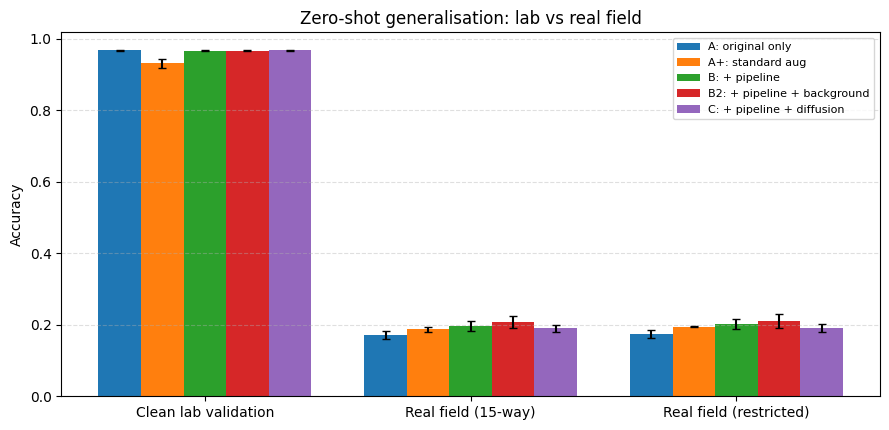


Per-class real-field accuracy % (mean over seeds):


,A: original only,A+: standard aug,B: + pipeline,B2: + pipeline + background,C: + pipeline + diffusion
Pepper__bell___Bacterial_spot (n=60),28.3,27.8,36.7,34.4,46.1
Pepper__bell___healthy (n=60),5.0,16.7,7.8,10.0,8.3
Potato___Early_blight (n=60),13.9,50.6,23.3,23.9,13.3
Potato___Late_blight (n=60),0.6,14.4,5.0,4.4,3.9
Tomato_Bacterial_spot (n=60),2.2,3.9,1.7,2.8,1.1
Tomato_Early_blight (n=60),36.1,28.9,53.9,51.1,49.4
Tomato_Late_blight (n=60),72.8,37.2,52.8,58.9,58.9
Tomato_Leaf_Mold (n=60),3.9,4.4,8.3,9.4,5.6
Tomato_Septoria_leaf_spot (n=60),23.3,17.8,21.7,21.1,17.2
Tomato_Spider_mites_Two_spotted_sp (n=2),0.0,0.0,0.0,0.0,0.0



Most-predicted classes of the best model (B2: + pipeline + background, seed 0), % of all predictions (a few dominant classes would indicate prediction collapse):
Tomato_Late_blight               41.2
Tomato_Early_blight              27.9
Tomato_Septoria_leaf_spot         7.6
Pepper__bell___Bacterial_spot     6.9
Potato___Early_blight             5.8


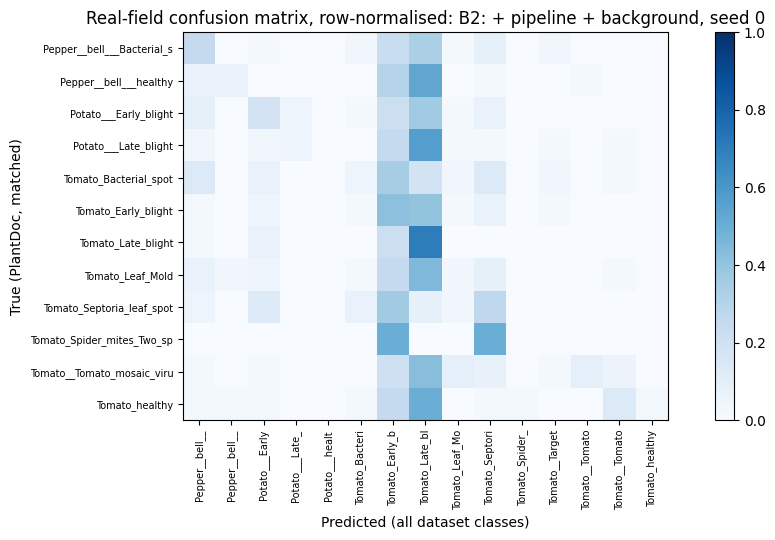

In [24]:
FIELD_ACC = None
if len(FIELD_ITEMS) == 0:
    print("Field evaluation skipped.")
else:
    y_field = np.array([y for p, y in FIELD_ITEMS])
    fc = np.array(field_classes)
    Y_COND["real field"] = y_field
    Y_COND["real field (restricted)"] = y_field
    field_rows = []
    for (key, seed), model in MODELS.items():
        probs = get_probabilities(model, FIELD_ITEMS)
        pred = probs.argmax(1)
        pred_r = fc[probs[:, fc].argmax(1)]
        PRED[(key, seed, "real field")] = pred
        PRED[(key, seed, "real field (restricted)")] = pred_r
        for tname, pr in [("real field", pred), ("real field (restricted)", pred_r)]:
            field_rows.append({"model": NAMES[key], "key": key, "seed": seed, "test": tname,
                               "accuracy": float((y_field == pr).mean()),
                               "f1": float(f1_score(y_field, pr, average="macro", labels=field_classes, zero_division=0))})
        print(f"  Model {key} | Seed {seed} | real-field acc: {100*(y_field == pred).mean():.1f}% | restricted: {100*(y_field == pred_r).mean():.1f}%")

    DF = DF[~DF.test.str.startswith("real field")]
    DF = pd.concat([DF, pd.DataFrame(field_rows)], ignore_index=True)
    DF.to_csv(RESULTS / "all_runs.csv", index=False)

    sel = ["clean", "real field", "real field (restricted)"]
    fm = DF[DF.test.isin(sel)].groupby(["model", "test"]).accuracy.mean().unstack()[sel].loc[model_names] * 100
    fs = DF[DF.test.isin(sel)].groupby(["model", "test"]).accuracy.std().unstack()[sel].loc[model_names].fillna(0) * 100
    FIELD_ACC = fm
    field_table = fm.round(1).astype(str) + " ± " + fs.round(1).astype(str)
    field_table["domain gap, clean - field (pts)"] = (fm["clean"] - fm["real field"]).round(1)
    print(f"\nLab vs. real-field accuracy % (mean ± std across {len(SEEDS)} seeds):")
    display(field_table); field_table.to_csv(RESULTS / "table_field.csv")

    maj = np.bincount(y_field).max() / len(y_field) * 100
    print(f"\nReference baselines: uniform guess over all {NC} classes = {100/NC:.1f}% | "
          f"uniform over the {len(field_classes)} present classes = {100/len(field_classes):.1f}% | "
          f"always-predict-majority-class = {maj:.1f}%")

    fig, ax = plt.subplots(figsize=(9, 4.4))
    width = 0.8 / len(model_names)
    for i, name in enumerate(model_names):
        ax.bar(np.arange(3) + i * width, fm.loc[name].values / 100, width, yerr=fs.loc[name].values / 100, capsize=3, label=name)
    ax.set_xticks(np.arange(3) + width * (len(model_names) - 1) / 2)
    ax.set_xticklabels(["Clean lab validation", f"Real field ({NC}-way)", "Real field (restricted)"])
    ax.set_ylabel("Accuracy"); ax.set_title("Zero-shot generalisation: lab vs real field"); ax.legend(fontsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.savefig(RESULTS / "field_comparison.png", dpi=150); plt.show()

    # ---- per-class accuracy, prediction collapse check, confusion matrix ----
    pc = {}
    for key in KEYS_TRAINED:
        pc[NAMES[key]] = [round(100 * np.mean([(PRED[(key, s, "real field")][y_field == c] == c).mean() for s in SEEDS]), 1)
                          for c in field_classes]
    PC = pd.DataFrame(pc, index=[f"{CLASSES[c][:34]} (n={int((y_field == c).sum())})" for c in field_classes])
    print("\nPer-class real-field accuracy % (mean over seeds):")
    display(PC); PC.to_csv(RESULTS / "field_per_class_accuracy.csv")

    BEST_FIELD_KEY = max(KEYS_TRAINED, key=lambda k: np.mean([(PRED[(k, s, "real field")] == y_field).mean() for s in SEEDS]))
    pred_best = PRED[(BEST_FIELD_KEY, SEEDS[0], "real field")]
    top = pd.Series([CLASSES[i] for i in pred_best]).value_counts(normalize=True).head(5) * 100
    print(f"\nMost-predicted classes of the best model ({NAMES[BEST_FIELD_KEY]}, seed {SEEDS[0]}), % of all predictions "
          f"(a few dominant classes would indicate prediction collapse):")
    print(top.round(1).to_string())

    cm = confusion_matrix(y_field, pred_best, labels=list(range(NC)))[field_classes, :].astype(float)
    cm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NC)); ax.set_xticklabels([c[:14] for c in CLASSES], rotation=90, fontsize=7)
    ax.set_yticks(range(len(field_classes))); ax.set_yticklabels([CLASSES[c][:26] for c in field_classes], fontsize=7)
    ax.set_xlabel("Predicted (all dataset classes)"); ax.set_ylabel("True (PlantDoc, matched)")
    ax.set_title(f"Real-field confusion matrix, row-normalised: {NAMES[BEST_FIELD_KEY]}, seed {SEEDS[0]}")
    plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout()
    plt.savefig(RESULTS / "field_confusion_matrix.png", dpi=150); plt.show()

## 18. Statistical Analysis: paired bootstrap CIs with seed-consistency check
For each comparison we bootstrap (2,000×) the **per-image accuracy difference** (averaged over seeds) to get a 95 % CI. Because the same images are scored by both models, the comparison is paired. A difference is called a **"clear improvement"** (or **"clear drop"**) only if *all three* hold: (i) the CI excludes 0, (ii) the mean effect is ≥ 1 percentage point, and (iii) the sign is the same in **every individual seed** (this guards against effects driven by one lucky run, since the image bootstrap alone ignores seed-to-seed variance). A CI that excludes 0 but fails (ii) or (iii) is reported as "significant but tiny / seed-inconsistent".

In [25]:
KEYS = KEYS_TRAINED
ALL_CONDS = [c for c in Y_COND if all((k, SEEDS[0], c) in PRED for k in KEYS)]
CORRECT = {(k, c): np.array([(PRED[(k, s, c)] == Y_COND[c]).astype(float) for s in SEEDS]) for k in KEYS for c in ALL_CONDS}
MIN_EFFECT = 1.0   # percentage points

def paired_ci(k1, k2, cond, n_boot=2000):
    a, b = CORRECT[(k1, cond)], CORRECT[(k2, cond)]
    d = b.mean(0) - a.mean(0)                                   # per-image, seed-averaged
    boots = d[np.random.default_rng(0).integers(0, len(d), (n_boot, len(d)))].mean(1)
    lo, hi = np.percentile(boots, [2.5, 97.5]) * 100
    m = d.mean() * 100
    per_seed = b.mean(1) - a.mean(1)
    pos, neg = bool((per_seed > 0).all()), bool((per_seed < 0).all())
    if lo > 0 and m >= MIN_EFFECT and pos:       v = "clear improvement"
    elif hi < 0 and m <= -MIN_EFFECT and neg:    v = "clear drop"
    elif lo > 0 or hi < 0:                       v = "significant but tiny / seed-inconsistent"
    else:                                        v = "no clear difference"
    return m, lo, hi, v

PAIRS = [("A", "AP", "Q1a: A+ (standard aug) vs A (none)"),
         ("A", "B", "Q1b: B (domain pipeline) vs A"),
         ("AP", "B", "Q1c: B (domain pipeline) vs A+ (standard aug)   <- key comparison"),
         ("B", "C", "Q2 : C (+ filtered diffusion) vs B"),
         ("B", "BG", "Q5a: B2 (+ background compositing) vs B"),
         ("AP", "BG", "Q5b: B2 (+ background compositing) vs A+ (standard aug)")]
stat_rows, lines = [], []
for k1, k2, title in PAIRS:
    if k1 in KEYS and k2 in KEYS:
        lines.append(title)
        for cond in ALL_CONDS:
            m, lo, hi, v = paired_ci(k1, k2, cond)
            stat_rows.append({"k1": k1, "k2": k2, "cond": cond, "diff": m, "lo": lo, "hi": hi, "verdict": v})
            tag = "in-family" if cond in IN_FAMILY else "OOD" if cond in OOD else "field" if cond.startswith("real") else "clean"
            lines.append(f"   {cond:24s} [{tag:9s}]: {m:+6.2f} pts  95% CI [{lo:+.2f}, {hi:+.2f}]  -> {v}")
        lines.append("")
STATS = pd.DataFrame(stat_rows)
STATS.to_csv(RESULTS / "paired_bootstrap_stats.csv", index=False)
summary2 = "\n".join(lines)
print(summary2)
(RESULTS / "auto_summary_bootstrap.txt").write_text(summary2)

Q1a: A+ (standard aug) vs A (none)
   clean                    [clean    ]:  -3.56 pts  95% CI [-4.01, -3.07]  -> clear drop
   lighting                 [in-family]:  +0.43 pts  95% CI [-1.03, +1.90]  -> no clear difference
   angle                    [in-family]: +13.67 pts  95% CI [+11.77, +15.50]  -> clear improvement
   growth                   [in-family]: +16.40 pts  95% CI [+14.17, +18.53]  -> clear improvement
   field mix                [in-family]: +23.73 pts  95% CI [+21.47, +25.87]  -> clear improvement
   quality                  [OOD      ]:  +9.67 pts  95% CI [+7.43, +11.93]  -> clear improvement
   color+noise              [OOD      ]:  +6.50 pts  95% CI [+4.73, +8.23]  -> significant but tiny / seed-inconsistent
   occlusion                [OOD      ]:  -4.07 pts  95% CI [-5.50, -2.77]  -> clear drop
   clutter                  [OOD      ]:  +9.57 pts  95% CI [+7.20, +11.97]  -> clear improvement
   real field               [field    ]:  +1.52 pts  95% CI [-0.97, +3.86

6883

## 19. Key Findings (auto-generated from this run's results)
The text below is **generated from the computed tables**, so every number is guaranteed to match the outputs above and nothing is hard-coded from an earlier run. Verdict words come from the paired-bootstrap rule in Section 18.

In [26]:
def fmt(key, cond):
    v = DF[(DF.key == key) & (DF.test == cond)].accuracy.values * 100
    return f"{v.mean():.1f} ± {v.std(ddof=1) if len(v) > 1 else 0:.1f}"

def stat_line(k1, k2, conds, label):
    sub = STATS[(STATS.k1 == k1) & (STATS.k2 == k2) & (STATS.cond.isin(conds))]
    if sub.empty:
        return None
    parts = []
    for verdict in ["clear improvement", "clear drop"]:
        s = sub[sub.verdict == verdict]
        if len(s):
            parts.append(f"**{verdict}** on {len(s)}/{len(sub)} (" + "; ".join(f"{r.cond} {r.diff:+.1f} pts" for r in s.itertuples()) + ")")
    rest = sub[~sub.verdict.isin(["clear improvement", "clear drop"])]
    if len(rest):
        parts.append(f"no clear / negligible difference on {len(rest)}/{len(sub)} (" + ", ".join(rest.cond) + ")")
    return f"  - *{label}:* " + "; ".join(parts) + "."

FIELD_CONDS = [c for c in ["real field", "real field (restricted)"] if c in ALL_CONDS]
md_lines = [f"### Results summary ({len(SEEDS)} seeds, 10 % data regime)", ""]
if QUICK_MODE:
    md_lines += ["> **QUICK_MODE was on: these are smoke-test numbers and must not be reported.**", ""]

md_lines += ["**Q1: Does the domain pipeline (B) improve robustness?**"]
for k1, nm in [("A", "vs no augmentation (A)"), ("AP", "vs standard augmentation (A+)")]:
    if k1 in KEYS and "B" in KEYS:
        md_lines.append(f"- B {nm}: clean accuracy {fmt('B','clean')} vs {fmt(k1,'clean')}.")
        for conds, lab in [(IN_FAMILY, "in-family stress tests"), (OOD, "out-of-distribution stress tests"), (FIELD_CONDS, "real field (PlantDoc)")]:
            ln = stat_line(k1, "B", conds, lab)
            if ln: md_lines.append(ln)
md_lines.append("  - *Reading guide:* in-family gains show interpolation robustness (the pipeline trains on the same kinds of shifts); the OOD and real-field rows are the evidence for genuine generalisation.")

md_lines += ["", "**Q2: Do confidence-filtered Stable Diffusion images (C) add gains over B?**"]
if "C" in KEYS and len(CANDS):
    per_class = (CANDS.groupby("class").accepted.mean() * 100).sort_values()
    md_lines.append(f"- Gate acceptance: {int(CANDS.accepted.sum())}/{len(CANDS)} ({100*CANDS.accepted.mean():.1f}%) across seeds at threshold(s) {sorted(set(THRESH.values()), reverse=True)}; "
                    f"lowest-acceptance classes: " + ", ".join(f"{c} ({v:.0f}%)" for c, v in per_class.head(3).items()) +
                    "; highest: " + ", ".join(f"{c} ({v:.0f}%)" for c, v in per_class.tail(3).items()) + ".")
    for conds, lab in [(IN_FAMILY, "in-family"), (OOD, "out-of-distribution"), (FIELD_CONDS, "real field")]:
        ln = stat_line("B", "C", conds, lab)
        if ln: md_lines.append(ln)
else:
    md_lines.append("- Model C was not trained (diffusion unavailable or nothing passed the gate).")

md_lines += ["", "**Q3: Rare-class recall** (mean recall over the 4 rarest classes; see the table in Section 17 for per-class values and validation counts)"]
for cond in ["clean", "growth", "quality", "occlusion", "clutter"]:
    md_lines.append(f"- {cond}: " + ", ".join(f"{NAMES[k].split(':')[0]} {100*minority_mean(k, cond):.0f}%" for k in KEYS) + ".")

md_lines += ["", "**Q4: Real-field generalisation (PlantDoc)**"]
if FIELD_ACC is not None:
    md_lines.append(f"- {len(FIELD_ITEMS)} real photos, {len(field_classes)} matched classes. {NC}-way accuracy: " +
                    ", ".join(f"{NAMES[k].split(':')[0]} {fmt(k, 'real field')}" for k in KEYS) +
                    ". Restricted to matched classes: " + ", ".join(f"{NAMES[k].split(':')[0]} {fmt(k, 'real field (restricted)')}" for k in KEYS) + ".")
    gap = {k: DF[(DF.key == k) & (DF.test == "clean")].accuracy.mean()*100 - DF[(DF.key == k) & (DF.test == "real field")].accuracy.mean()*100 for k in KEYS}
    md_lines.append("- Lab-to-field gap (clean minus field, pts): " + ", ".join(f"{NAMES[k].split(':')[0]} {v:.1f}" for k, v in gap.items()) +
                    ". A large gap means lab-trained classifiers remain unreliable on field photos regardless of augmentation; absolute field accuracy should be read against the reference baselines printed in Section 17.")
    for k1, k2, lab in [("A", "B", "B vs A"), ("AP", "B", "B vs A+"), ("B", "BG", "B2 vs B"), ("AP", "BG", "B2 vs A+"), ("B", "C", "C vs B")]:
        if k1 in KEYS and k2 in KEYS:
            ln = stat_line(k1, k2, FIELD_CONDS, lab)
            if ln: md_lines.append(ln)
else:
    md_lines.append("- Field evaluation was skipped (PlantDoc unavailable or demo dataset).")

md_lines += ["", "**Q5: Does background compositing (B2) help?**"]
if "BG" in KEYS:
    for k1, lab in [("B", "B2 vs B"), ("AP", "B2 vs A+")]:
        for conds, cl in [(IN_FAMILY, "in-family"), (OOD, "OOD"), (FIELD_CONDS, "real field")]:
            ln = stat_line(k1, "BG", conds, f"{lab}, {cl}")
            if ln: md_lines.append(ln.replace("  - ", "- ", 1))

grp = pd.DataFrame({"OOD": [DF[(DF.key == k) & DF.test.isin(OOD)].accuracy.mean() * 100 for k in KEYS]}, index=[NAMES[k] for k in KEYS])
md_lines += ["", f"**Overall:** highest mean OOD-stress accuracy: **{grp.OOD.idxmax()}** ({grp.OOD.max():.1f} %)." +
             (f" Highest real-field accuracy: **{NAMES[BEST_FIELD_KEY]}**." if FIELD_ACC is not None else "")]

findings_md = "\n".join(md_lines)
(RESULTS / "key_findings.md").write_text(findings_md)
display(Markdown(findings_md))

### Results summary (3 seeds, 10 % data regime)

**Q1: Does the domain pipeline (B) improve robustness?**
- B vs no augmentation (A): clean accuracy 96.6 ± 0.1 vs 96.7 ± 0.2.
  - *in-family stress tests:* **clear improvement** on 4/4 (lighting +4.1 pts; angle +15.6 pts; growth +36.4 pts; field mix +45.9 pts).
  - *out-of-distribution stress tests:* **clear improvement** on 2/4 (quality +19.6 pts; color+noise +11.5 pts); no clear / negligible difference on 2/4 (occlusion, clutter).
  - *real field (PlantDoc):* **clear improvement** on 2/2 (real field +2.6 pts; real field (restricted) +2.8 pts).
- B vs standard augmentation (A+): clean accuracy 96.6 ± 0.1 vs 93.2 ± 1.2.
  - *in-family stress tests:* **clear improvement** on 4/4 (lighting +3.7 pts; angle +1.9 pts; growth +20.0 pts; field mix +22.1 pts).
  - *out-of-distribution stress tests:* **clear improvement** on 2/4 (quality +9.9 pts; occlusion +4.7 pts); **clear drop** on 1/4 (clutter -7.5 pts); no clear / negligible difference on 1/4 (color+noise).
  - *real field (PlantDoc):* no clear / negligible difference on 2/2 (real field, real field (restricted)).
  - *Reading guide:* in-family gains show interpolation robustness (the pipeline trains on the same kinds of shifts); the OOD and real-field rows are the evidence for genuine generalisation.

**Q2: Do confidence-filtered Stable Diffusion images (C) add gains over B?**
- Gate acceptance: 464/675 (68.7%) across seeds at threshold(s) [0.8]; lowest-acceptance classes: Tomato__Target_Spot (16%), Tomato_Spider_mites_Two_spotted_spider_mite (18%), Tomato_Leaf_Mold (33%); highest: Tomato__Tomato_mosaic_virus (93%), Tomato_Early_blight (93%), Potato___Early_blight (100%).
  - *in-family:* no clear / negligible difference on 4/4 (lighting, angle, growth, field mix).
  - *out-of-distribution:* **clear improvement** on 1/4 (color+noise +17.9 pts); no clear / negligible difference on 3/4 (quality, occlusion, clutter).
  - *real field:* no clear / negligible difference on 2/2 (real field, real field (restricted)).

**Q3: Rare-class recall** (mean recall over the 4 rarest classes; see the table in Section 17 for per-class values and validation counts)
- clean: A 98%, A+ 96%, B 97%, B2 98%, C 98%.
- growth: A 48%, A+ 71%, B 94%, B2 93%, C 96%.
- quality: A 52%, A+ 56%, B 70%, B2 64%, C 69%.
- occlusion: A 97%, A+ 93%, B 99%, B2 97%, C 98%.
- clutter: A 39%, A+ 40%, B 44%, B2 47%, C 49%.

**Q4: Real-field generalisation (PlantDoc)**
- 656 real photos, 12 matched classes. 15-way accuracy: A 17.2 ± 1.2, A+ 18.7 ± 0.8, B 19.8 ± 1.4, B2 20.8 ± 1.7, C 19.0 ± 0.9. Restricted to matched classes: A 17.4 ± 1.2, A+ 19.5 ± 0.2, B 20.2 ± 1.4, B2 21.1 ± 1.9, C 19.2 ± 1.1.
- Lab-to-field gap (clean minus field, pts): A 79.6, A+ 74.5, B 76.8, B2 75.9, C 77.8. A large gap means lab-trained classifiers remain unreliable on field photos regardless of augmentation; absolute field accuracy should be read against the reference baselines printed in Section 17.
  - *B vs A:* **clear improvement** on 2/2 (real field +2.6 pts; real field (restricted) +2.8 pts).
  - *B vs A+:* no clear / negligible difference on 2/2 (real field, real field (restricted)).
  - *B2 vs B:* no clear / negligible difference on 2/2 (real field, real field (restricted)).
  - *B2 vs A+:* no clear / negligible difference on 2/2 (real field, real field (restricted)).
  - *C vs B:* no clear / negligible difference on 2/2 (real field, real field (restricted)).

**Q5: Does background compositing (B2) help?**
- *B2 vs B, in-family:* no clear / negligible difference on 4/4 (lighting, angle, growth, field mix).
- *B2 vs B, OOD:* **clear improvement** on 1/4 (clutter +4.7 pts); no clear / negligible difference on 3/4 (quality, color+noise, occlusion).
- *B2 vs B, real field:* no clear / negligible difference on 2/2 (real field, real field (restricted)).
- *B2 vs A+, in-family:* **clear improvement** on 4/4 (lighting +3.3 pts; angle +1.8 pts; growth +19.7 pts; field mix +21.6 pts).
- *B2 vs A+, OOD:* **clear improvement** on 2/4 (quality +8.8 pts; occlusion +4.7 pts); **clear drop** on 1/4 (clutter -2.9 pts); no clear / negligible difference on 1/4 (color+noise).
- *B2 vs A+, real field:* no clear / negligible difference on 2/2 (real field, real field (restricted)).

**Overall:** highest mean OOD-stress accuracy: **C: + pipeline + diffusion** (72.9 %). Highest real-field accuracy: **B2: + pipeline + background**.

## 20. Limitations & Future Work

### Limitations
- **Lab-to-field gap.** All models are trained on uniform-background lab photos (PlantVillage). Augmentation can narrow, but does not close, the gap to cluttered outdoor photos; the PlantDoc tables above quantify what remains. PlantDoc itself is small, noisily labelled and only covers the classes that map one-to-one between datasets.
- **Growth stage is a visual proxy.** The dataset has no growth-stage labels, so the transform approximates appearance (scale + chlorophyll tint) rather than real plant phenology; we therefore cannot measure true growth-stage generalisation. Likewise, camera-angle augmentation is 2-D (rotation / shear / projective warp), not true 3-D viewpoint change.
- **Stress tests are synthetic.** In-family tests share transform families with training and only measure interpolation robustness; the OOD tests and PlantDoc are the more meaningful evidence. The `clutter` test shares a leaf-segmentation helper with B2 and is therefore only partly independent for that model.
- **Leakage control is perceptual, not semantic.** Near-duplicate grouping catches re-saved, rescaled, rotated and mirrored copies of a photo, but not different photographs of the same physical leaf (capture metadata is unavailable). Clean validation accuracy may remain somewhat optimistic.
- **Segmentation is heuristic.** Leaf masks use colour distance from the border colour; unusual backgrounds can fail, in which case a standard pipeline copy is substituted (the fallback rate is printed in Section 10).
- **Diffusion limits.** Unconditioned Stable Diffusion v1.4 Img2Img at low strength tends to preserve the studio background and can smooth fine-grained symptoms (small spots, mites). The confidence gate uses Model A, so accepted images are those the baseline already finds easy, limiting true diversity. Only a small number of images is generated per class, and C's diffusion share is a fixed design choice (`DIFF_SHARE`).
- **Statistical scope.** Three seeds (each with its own data subset) and one backbone (ResNet-18) on a single dataset family; conclusions may not transfer to other crops, architectures or labelling regimes.

### Future work
- **Structure-preserving background synthesis** (ControlNet / inpainting) that replaces the background with realistic soil and canopy while locking the leaf geometry and lesion masks.
- **Few-shot real-field fine-tuning:** combine the augmented lab pipeline with 5-10 real field shots per class.
- **Class-balanced generative sampling** with a stronger / independent filter (an ensemble or CLIP-based consistency score) instead of Model A alone.
- **Better growth-stage modelling** using datasets with stage metadata, and 3-D viewpoint augmentation.

## 21. Production Module Export & Round-Trip Test
`cropaugment.py` was already written in Section 7 and used by every experiment. We now save the best classifier's weights and class list, then **re-load them through the module** to prove the exported package works end to end.

In [27]:
# Choose the model to ship: best real-field accuracy if available, otherwise best OOD accuracy
if FIELD_ACC is not None:
    SHIP_KEY = BEST_FIELD_KEY
else:
    SHIP_KEY = max(KEYS_TRAINED, key=lambda k: DF[(DF.key == k) & DF.test.isin(OOD)].accuracy.mean())
print("Shipping model:", NAMES[SHIP_KEY], "(seed", SEEDS[0], ")")

torch.save(MODELS[(SHIP_KEY, SEEDS[0])].state_dict(), "cropaugment_resnet18.pt")
json.dump(CLASSES, open("classes.json", "w"))

# Round-trip test through the exported module
importlib.reload(cropaugment)
clf, clf_classes = cropaugment.load_classifier("cropaugment_resnet18.pt", "classes.json")
test_path, test_label = VAL_ITEMS[0]
print("Round-trip prediction:", cropaugment.predict(clf, clf_classes, Image.open(test_path)), "| true class:", CLASSES[test_label])

# Augmentation round-trip through the module's folder API (3 classes x 2 images)
tmp_in = BASE / "module_test_in"
tmp_out = BASE / "module_test_out"
for p, y in VAL_ITEMS[:6]:
    (tmp_in / CLASSES[y]).mkdir(parents=True, exist_ok=True)
    Image.open(p).convert("RGB").save(tmp_in / CLASSES[y] / Path(p).name)
n_written = cropaugment.augment_folder(tmp_in, tmp_out, copies=2, seed=0, with_background=True)
print(f"augment_folder wrote {n_written} images via the exported module.")

Shipping model: B2: + pipeline + background (seed 0 )
Round-trip prediction: [('Pepper__bell___Bacterial_spot', 0.9564985632896423), ('Tomato__Target_Spot', 0.02791021019220352), ('Tomato_Septoria_leaf_spot', 0.004661777056753635)] | true class: Pepper__bell___Bacterial_spot
augment_folder wrote 12 images via the exported module.


### Interactive Gradio Web Demo
A two-tab demo: (1) generate lighting / angle / growth / background variants of an uploaded leaf photo; (2) classify a photo with the shipped ResNet-18 and see the top-3 confidence scores. The demo launches a temporary public link.

In [28]:
try:
    import gradio as gr

    def aug_demo(img, n, with_bg):
        rng = random.Random()
        outs = []
        for i in range(int(n)):
            res = None
            if with_bg and i % 2 == 1:
                res, _ = augment_background(img.convert("RGB"), rng)
            outs.append(res if res is not None else augment_one(img.convert("RGB"), rng)[0])
        return outs

    def clf_demo(img):
        return {c: p for c, p in cropaugment.predict(clf, clf_classes, img, topk=3)}

    with gr.Blocks(title="CropAugment AI") as demo:
        gr.Markdown("# CropAugment AI\nDomain-aware crop-disease augmentation + ResNet-18 classifier")
        with gr.Tab("Augment"):
            inp = gr.Image(type="pil", label="Leaf photo")
            n = gr.Slider(1, 8, value=6, step=1, label="Variants")
            bg = gr.Checkbox(value=True, label="Include background-composited variants")
            gal = gr.Gallery(label="Augmented variants")
            gr.Button("Generate").click(aug_demo, [inp, n, bg], gal)
        with gr.Tab("Classify"):
            inp2 = gr.Image(type="pil", label="Leaf photo")
            lab = gr.Label(num_top_classes=3, label="Prediction (top-3 confidence)")
            gr.Button("Classify").click(clf_demo, inp2, lab)
    demo.launch(share=True)
except Exception as e:
    print("Gradio demo could not be launched:", e)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://30df059eb25a4e0ab5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 22. Export All Results & Artifacts for Submission

In [29]:
settings = {
    "QUICK_MODE": QUICK_MODE, "SEEDS": SEEDS, "LOW_FRAC": LOW_FRAC, "COPIES": COPIES, "BG_COPIES": BG_COPIES,
    "EPOCHS": EPOCHS, "SAMPLES_PER_EPOCH": SAMPLES_PER_EPOCH, "LR": LR, "BATCH": BATCH, "TEST_N": TEST_N,
    "NEAR_DUP_T": NEAR_DUP_T, "near_dup_groups_gt1": int((np.bincount(GROUPS) > 1).sum()),
    "DIFF_PER_CLASS_PER_SEED": DIFF_PER_CLASS, "DIFF_STRENGTH": DIFF_STRENGTH, "DIFF_SHARE": DIFF_SHARE,
    "FILTER_CONF": FILTER_CONF, "FILTER_USED_PER_SEED": {str(k): v for k, v in THRESH.items()},
    "unique_images": len(ALL_ITEMS), "train": len(TRAIN_ITEMS), "validation": len(VAL_ITEMS),
    "low_data_photos_per_seed": {str(s): len(LOW[s]) for s in SEEDS},
    "pipeline_photos_per_seed": {str(s): len(PIPE[s]) for s in SEEDS},
    "background_photos_per_seed": {str(s): len(BGI[s]) for s in SEEDS},
    "diffusion_generated": int(len(CANDS)), "diffusion_accepted": int(sum(len(v) for v in ACCEPTED.values())),
    "field_photos": len(FIELD_ITEMS), "field_classes": len(set(y for p, y in FIELD_ITEMS)),
    "shipped_model": NAMES[SHIP_KEY],
}
(RESULTS / "settings.json").write_text(json.dumps(settings, indent=2))

zip_path = BASE / "CropAugmentAI_Submission.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RESULTS.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(BASE))
    for p in list(PIPE_DIR.rglob("*.jpg"))[:150]:
        z.write(p, Path("pipeline_sample") / p.parents[1].name / p.parent.name / p.name)
    for p in list(BG_DIR.rglob("*.jpg"))[:150]:
        z.write(p, Path("background_sample") / p.parents[1].name / p.parent.name / p.name)
    for s in SEEDS:
        for path, label in ACCEPTED[s]:
            z.write(path, Path("accepted_diffusion") / f"seed{s}" / Path(path).parent.name / Path(path).name)
    for extra in ["cropaugment.py", "cropaugment_resnet18.pt", "classes.json"]:
        if Path(extra).exists():
            z.write(extra, extra)

print(f"Submission archive created: {zip_path} ({zip_path.stat().st_size / 1e6:.2f} MB)")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Run inside Google Colab to trigger the automatic browser download.")

Submission archive created: /content/CropAugmentAI/CropAugmentAI_Submission.zip (104.88 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>